# Assignment Module 2: Aircraft Classification

Author: Francesca Lonardo

The goal of this assignment is to implement a neural network that classifies images of 100 aircraft model variants from the [Fine-Grained Visual Classification of Aircraft (**FGVC-Aircraft**) dataset](https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/). The assignment is divided into two parts: first, you will be asked to implement your own neural network for image classification from scratch; then, you will fine-tune a pretrained network provided by PyTorch.

![](https://raw.githubusercontent.com/CVLAB-Unibo/ipcv-assignment-2/master/fgvc_aircraft_variants.svg)


## Dataset

Download and acces the dataset through its official [PyTorch `FGVCAircraft` class](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.FGVCAircraft.html) (by setting its constructor argument `annotation_level` to `'variant'`).

# Part 1: design your own network

Your goal is to implement a convolutional neural network for image classification and train it from scratch on `FGVCAircraft`. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~50%. You are free to achieve this however you want, except for a few rules you must follow:

- Compile this notebook by displaying the results obtained by the best model you found throughout your experimentation; then show how, by removing some of its components, its performance drops. In other words, do an *ablation study* to prove that your design choices have a positive impact on the final result.

- Do not instantiate an off-the-self PyTorch network. Instead, construct your network as a composition of existing PyTorch layers. In more concrete terms, you can use e.g. `torch.nn.Linear`, but you cannot use e.g. `torchvision.models.alexnet`.

- Show your results and ablations with plots, tables, images, etc. — the clearer, the better.

Don't be too concerned with your model performance: the ~50% is just to give you an idea of when to stop. Keep in mind that a thoroughly justified model with lower accuracy will be rewarded more points than a poorly experimentally validated model with higher accuracy.

## Summary of the approach

With only about 33 images per class, this dataset carries a high risk of overfitting, and the risk grows with every component added to the network.
For this reason, the network was not designed all at once: we started from a simple, reasonable baseline (a minimal 4-block CNN, one convolution per block, no regularization) and built it up incrementally, adding one component at a time and letting the result of each step guide the next choice. Once the design was settled, the final model was fixed and a formal ablation study was run, removing one component at a time and measuring the resulting drop. The development runs are not reported in this notebook: the ablation study below is what validates each choice quantitatively.

The development path that led to the final model was the following:

- A minimal 4-block CNN with no regularization overfitted almost immediately, and its validation loss diverged rather than just plateauing.
- **Batch Normalization** stabilized training and roughly doubled validation accuracy, but the model still overfitted heavily, so a simple **horizontal flip** was added next.
- **Global Average Pooling** was meant to shrink the large fully-connected classifier, but on its own it slightly lowered accuracy, likely because it discards spatial information this task needs.
- Adding a **5th convolutional block** together with GAP resolved this: the extra depth compensates for the lost spatial detail, and the model surpassed every previous result.
- The validation curve then oscillated, a sign of a learning rate too high near a good minimum, so a **learning-rate scheduler** (`ReduceLROnPlateau`) was introduced to dampen the oscillation.
- **Weight decay** and then **Dropout** were added next, the latter placed only after GAP to avoid its known conflict with Batch Normalization. The ablation study shows that the first mainly improves optimization, while the second narrows the train/validation gap.
- **Richer augmentation** (rotation, color jitter, random erasing) was the single most effective lever against overfitting, which remains the dominant problem on a dataset this small.
- Since training accuracy was still approaching 100% in several runs, **label smoothing** was added to discourage over-confident predictions. It gave a small gain during development, which the ablation study shows to be within the noise of the validation set.

The learning-rate schedule was revisited last. `ReduceLROnPlateau` only lowers the learning rate once validation performance stalls, which happened late in training and made every experiment slower than necessary. It was therefore replaced with **OneCycleLR**, which ramps the learning rate up to a high peak and then anneals it on a fixed, pre-determined schedule.

The final architecture (5 convolutional blocks, Batch Normalization, Global Average Pooling, Dropout, a single linear classifier) is detailed in the CNN architecture section below. It reaches **53.41% validation accuracy (52.36% test)**, above the ~50% target.

## Import

In [ ]:
import copy
import json
import matplotlib.pyplot as plt
import numpy as np
import random
import torch
import torch.nn as nn
import pandas as pd

from pathlib import Path
from tqdm.notebook import tqdm

from torch.utils.data import DataLoader
from torchsummary import summary
from torchvision import transforms as T
from torchvision.datasets import FGVCAircraft
from torchvision.models import resnet18, ResNet18_Weights

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## Reproducibility

This function fixes every source of randomness, so that experiments are repeatable.
It is called again at the start of every experiment below, so that each model starts from the same initial weights and sees the same shuffling order.

In [ ]:
def fix_random(seed: int) -> None:
    """Fix all the possible sources of randomness.

    Args:
        seed: the seed to use.
    """
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

fix_random(42)

## Runtime settings

Selects the GPU if one is available, otherwise falls back to CPU.

In [ ]:
device = "cpu"
if torch.cuda.is_available():
  print("All good, a GPU is available")
  device = torch.device("cuda:0")
else:
  print("Please set GPU via Edit -> Notebook Settings")


All good, a GPU is available


## Dataset analysis

Before designing any preprocessing step, it is worth looking at the data directly. We first load the raw training split with no transformation, and print its size together with the dimensions of a single example. We then display some random samples to spot anything that a fixed pipeline should account for, like image size, aspect ratio, and any artifact that is not part of the aircraft itself.

100%|██████████| 2.75G/2.75G [02:09<00:00, 21.2MB/s]


Number of training samples: 3334
Example image size (PIL, width x height): (1024, 695)


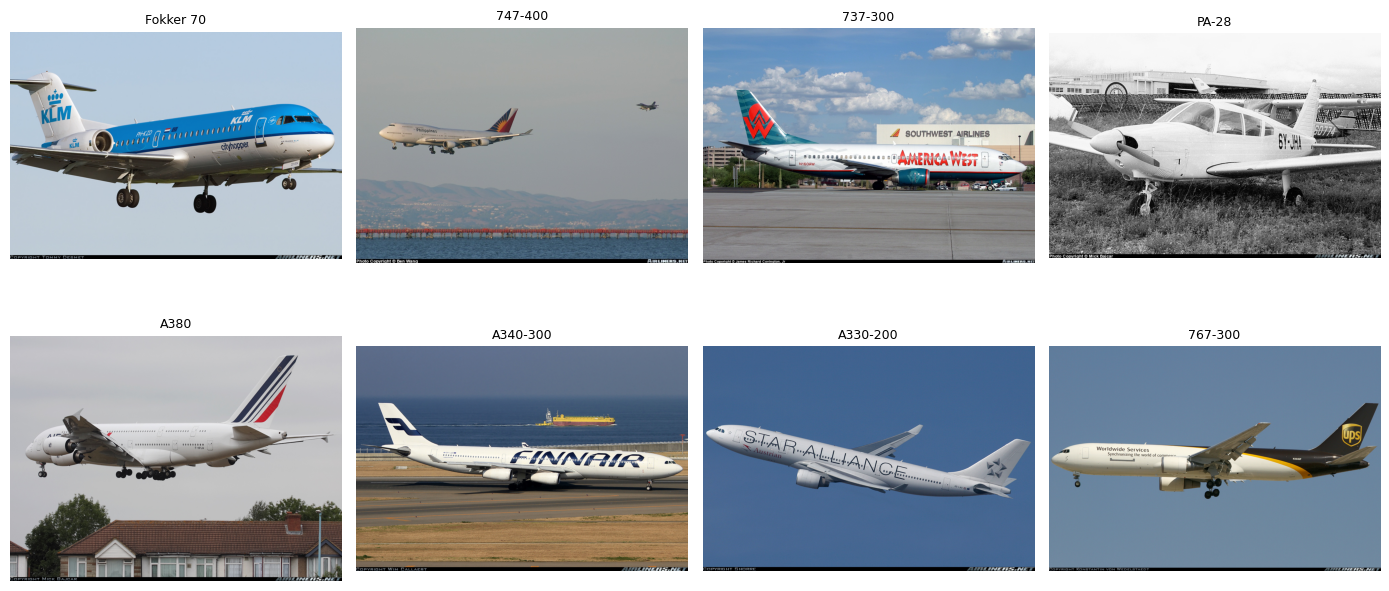

In [ ]:
data_raw = FGVCAircraft(
    root="/data/",
    split="train",
    annotation_level="variant",
    download=True
)

print(f"Number of training samples: {len(data_raw)}")
print(f"Example image size (PIL, width x height): {data_raw[0][0].size}")

# 8 random images, just to get a feel for the dataset
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
indices = random.sample(range(len(data_raw)), 8)

for ax, idx in zip(axes.flatten(), indices):
    img, label = data_raw[idx]
    ax.imshow(img)
    ax.set_title(data_raw.classes[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

We can already notice two things that will drive the preprocessing choices below: every image carries a thin copyright banner along the bottom edge, and images come in different sizes. Before deciding how to resize them, we check whether the dataset is otherwise well-behaved.

In [ ]:
labels_raw = [label for _, label in data_raw]
counts = np.bincount(labels_raw)
print(f"Number of classes: {len(counts)}")
print(f"Min images per class: {counts.min()}")
print(f"Max images per class: {counts.max()}")
print(f"Mean images per class: {counts.mean():.1f}")

Number of classes: 100
Min images per class: 33
Max images per class: 34
Mean images per class: 33.3


The dataset contains 100 classes with an almost identical number of examples each (33-34 images per class in the training split). Since there is no significant class imbalance, no re-weighting or resampling technique is required later on.

Next, we look at how the original image dimensions are distributed, on a random sample, to decide how to resize them without distorting or cropping away useful content.

In [ ]:
# original image dimensions, to decide on resize/crop
sample_indices = random.sample(range(len(data_raw)), 500)
widths, heights = [], []

for idx in sample_indices:
    img, _ = data_raw[idx]
    w, h = img.size
    widths.append(w)
    heights.append(h)

aspect_ratios = [w / h for w, h in zip(widths, heights)]

print(f"Width:  min= {min(widths)}, max= {max(widths)}, mean= {np.mean(widths):.1f}")
print(f"Height: min= {min(heights)}, max= {max(heights)}, mean= {np.mean(heights):.1f}")
print(f"Mean aspect ratio: {np.mean(aspect_ratios):.2f}")

Width:  min= 800, max= 1600, mean= 1113.3
Height: min= 434, max= 1117, mean= 756.5
Mean aspect ratio: 1.47


The measured sizes are not used as the input size: images of about 1100×750 pixels would make training too slow and memory-hungry for a network trained from scratch. They are used to choose the shape instead: since the aspect ratio is about 1.5, all images are resized to a rectangle with a similar ratio (112×160, ratio 1.43), small enough to keep training fast.

## Preprocessing

We remove the copyright banner, resize every image to a fixed rectangular size (instead of a square, given the aspect ratio measured above), and normalize the three color channels using statistics computed on the training set itself.

Normalizing pixel values to zero mean and unit variance keeps the input in the range the network's weight initialization assumes, and helps gradients stay well-scaled from the very first layer onward.

In [ ]:
img_width, img_height = 160, 112

def crop_copyright_banner(img):
    """Removes the copyright banner at the bottom of the image (last 20px)."""
    w, h = img.size
    return img.crop((0, 0, w, h - 20))


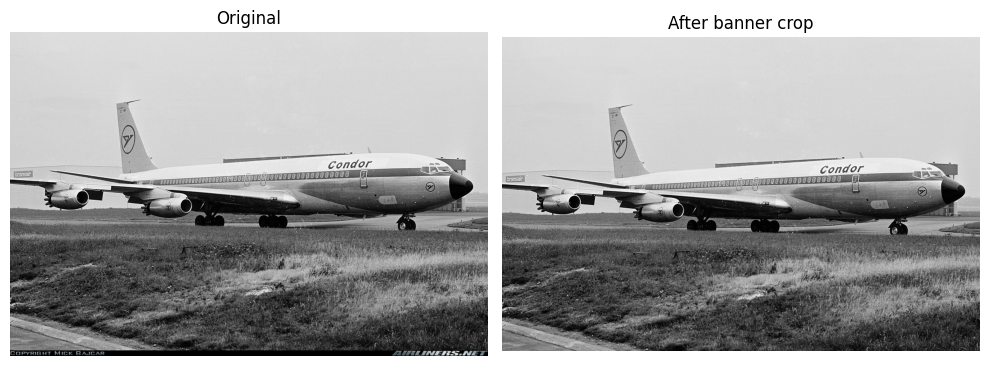

In [ ]:
# visual check: before/after removing the banner
img, label = data_raw[0]
img_cropped = crop_copyright_banner(img)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(img_cropped)
axes[1].set_title("After banner crop")
axes[1].axis("off")

plt.tight_layout()
plt.show()


We now compute the per-channel mean and standard deviation on the training set, using the same crop/resize pipeline that will be used at training time (so that the statistics match what the network will actually see).

Since the standard deviation is averaged over per-image values, it slightly underestimates the true dataset-wide standard deviation; the difference is negligible for normalization purposes.

In [ ]:
stats_transform = T.Compose([
    T.Lambda(crop_copyright_banner),
    T.Resize((img_height, img_width)),
    T.ToTensor()
])

data_for_stats = FGVCAircraft(
    root="/data/",
    split="train",
    annotation_level="variant",
    transform=stats_transform,
    download=True
)

loader_for_stats = DataLoader(data_for_stats, batch_size=64, shuffle=False)

mean = torch.zeros(3)
std = torch.zeros(3)
n_samples = 0

for imgs, _ in loader_for_stats:
    batch_samples = imgs.size(0)
    imgs = imgs.view(batch_samples, 3, -1)
    mean += imgs.mean(dim=2).sum(dim=0)
    std += imgs.std(dim=2).sum(dim=0)
    n_samples += batch_samples

mean /= n_samples
std /= n_samples

print(f"Mean: {mean}")
print(f"Std: {std}")


Mean: tensor([0.4878, 0.5193, 0.5435])
Std: tensor([0.1748, 0.1725, 0.1960])


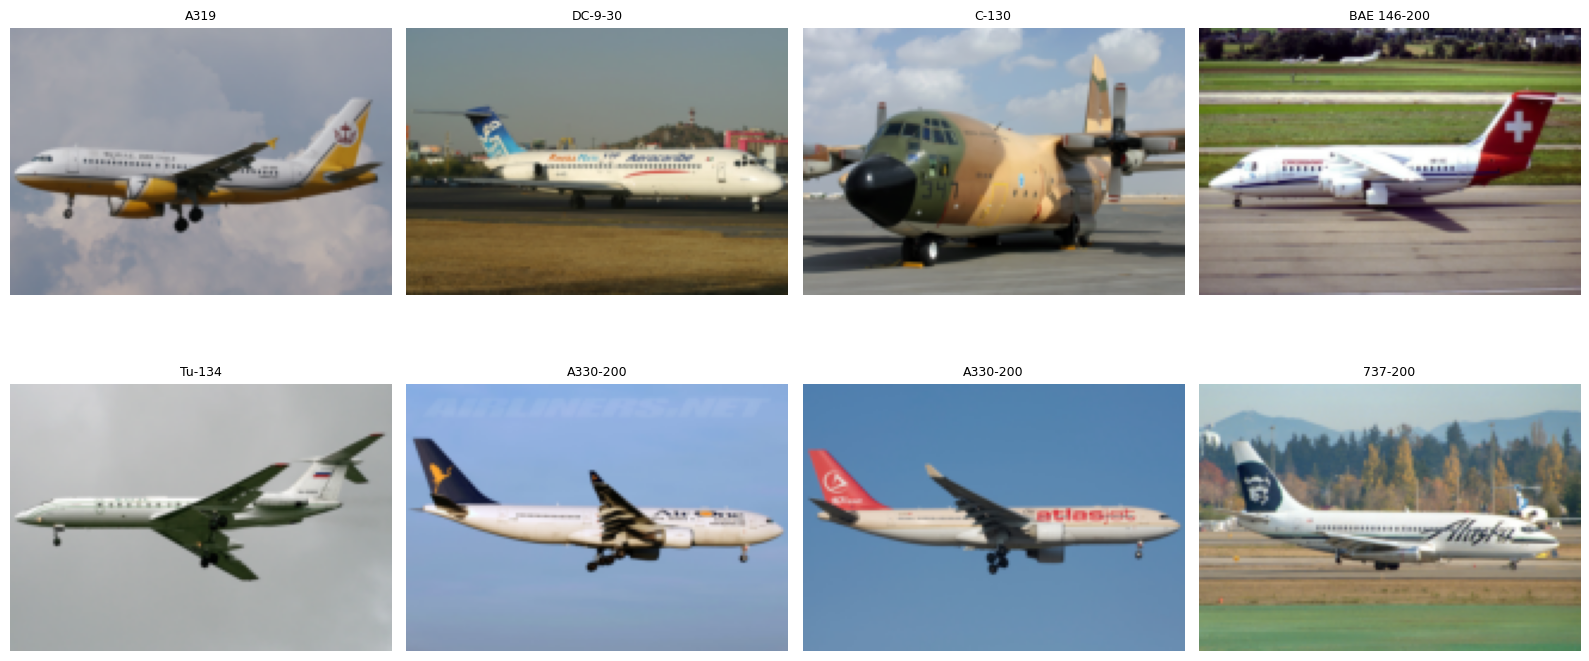

In [ ]:
# visual check
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
sample_check = random.sample(range(len(data_raw)), 8)

preview_transform = T.Compose([
    T.Lambda(crop_copyright_banner),
    T.Resize((img_height, img_width))
])

for ax, idx in zip(axes.flatten(), sample_check):
    img, label = data_raw[idx]
    img_processed = preview_transform(img)
    ax.imshow(img_processed)
    ax.set_title(data_raw.classes[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


With the crop, resize and normalization decided, we define the transform pipelines and build the actual datasets. Two training transforms are kept: one with no augmentation (used only in the no-augmentation ablation) and one with the final augmentation (horizontal flip, small rotation, color jitter and random erasing), used by every other experiment.

In [ ]:
mean = mean.tolist()
std = std.tolist()

data_transforms = {
    # resize and normalization only, no augmentation
    "train_base": T.Compose([
        T.Lambda(crop_copyright_banner),
        T.Resize((img_height, img_width)),
        T.ToTensor(),
        T.Normalize(mean, std)
    ]),
    # the final augmentation applied (horizontal flip, small rotation, color jitter and random erasing)
    "train_final": T.Compose([
        T.Lambda(crop_copyright_banner),
        T.Resize((img_height, img_width)),
        T.RandomHorizontalFlip(),
        T.RandomRotation(degrees=10),
        T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        T.ToTensor(),
        T.Normalize(mean, std),
        T.RandomErasing(p=0.3, scale=(0.02, 0.1))
    ]),
    # validation/test: no augmentation, ever
    "test": T.Compose([
        T.Lambda(crop_copyright_banner),
        T.Resize((img_height, img_width)),
        T.ToTensor(),
        T.Normalize(mean, std)
    ])
}

# training set WITHOUT augmentation (baseline and other "pure" experiments)
data_train_base = FGVCAircraft(
    root="/data/", split="train", annotation_level="variant",
    transform=data_transforms["train_base"], download=True
)

# training set WITH the final augmentation recipe
data_train_final = FGVCAircraft(
    root="/data/", split="train", annotation_level="variant",
    transform=data_transforms["train_final"], download=True
)

# validation set (same transform as test)
data_val = FGVCAircraft(
    root="/data/", split="val", annotation_level="variant",
    transform=data_transforms["test"], download=True
)

# test set
data_test = FGVCAircraft(
    root="/data/", split="test", annotation_level="variant",
    transform=data_transforms["test"], download=True
)

n_classes = len(data_train_base.classes)
print(f"Train size: {len(data_train_base)}")
print(f"Train size (final augmentation): {len(data_train_final)}")
print(f"Val size: {len(data_val)}")
print(f"Test size: {len(data_test)}")
print(f"Number of classes: {n_classes}")


Train size: 3334
Train size (final augmentation): 3334
Val size: 3333
Test size: 3333
Number of classes: 100


The augmentation is applied on the fly: the dataset still contains 3334 training images, but at every epoch each image is transformed at random, so the network sees a different version of it each time.

## Data loaders

In [ ]:
batch_size = 64

loader_train_base = DataLoader(data_train_base, batch_size=batch_size, shuffle=True, pin_memory=True)
loader_train_final = DataLoader(data_train_final, batch_size=batch_size, shuffle=True, pin_memory=True)
loader_test = DataLoader(data_test, batch_size=batch_size, shuffle=False, pin_memory=True)

imgs, labels = next(iter(loader_train_base))
print(f"Image batch: {imgs.shape}")
print(f"Label batch: {labels.shape}")

# caching the validation set once in memory instead of re-reading and re-transforming the JPEGs at every epoch of every experiment
val_imgs, val_labels = [], []
for imgs, labels in DataLoader(data_val, batch_size=64, shuffle=False):
    val_imgs.append(imgs)
    val_labels.append(labels)
val_cached = torch.utils.data.TensorDataset(torch.cat(val_imgs), torch.cat(val_labels))
loader_val_fast = DataLoader(val_cached, batch_size=64, shuffle=False)
print("Cached validation samples:", len(val_cached))


Image batch: torch.Size([64, 3, 112, 160])
Label batch: torch.Size([64])
Cached validation samples: 3333


## CNN architecture

The network is a plain stack of convolutional blocks, in the style of AlexNet and VGG, with no skip connections. Its final configuration (all flags enabled) is:

- **Five convolutional blocks**, with channels doubling at every stage: 32 → 64 → 128 → 256 → 512. Each block is a single `Conv2d(kernel_size=3, padding=1) - BatchNorm2d - ReLU`. 3×3 kernels are used throughout, following the common practice (popularized by VGG) of preferring small kernels over larger ones because they require fewer parameters per layer while still covering a meaningful receptive field once combined with pooling across the network's depth.
- **Max-pooling (2×2)** after every block, halving the spatial resolution five times: 112×160 → 56×80 → 28×40 → 14×20 → 7×10 → 3×5.
- **Global Average Pooling**, collapsing the final 512×3×5 feature map to a single 512-dimensional vector per image, instead of flattening it directly. This keeps the final classifier small regardless of the input resolution.
- **Dropout (p=0.5)**, applied to that 512-dimensional vector, right before the classifier.
- **A single linear classifier**, mapping the 512 features to the 100 aircraft classes.

In [ ]:
def get_conv_block(in_channels, out_channels, use_bn=False):
    """A reusable Conv-BN-ReLU block. use_bn toggles Batch Normalization on/off,
    so the same block can be reused across the whole ablation study."""
    layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)]
    if use_bn:
        layers.append(nn.BatchNorm2d(out_channels))
    layers.append(nn.ReLU())
    return nn.Sequential(*layers)


In [ ]:
class AircraftCNN(nn.Module):
    """Our VGG-style CNN.

    Args:
        n_classes: number of output classes.
        use_bn: whether to use Batch Normalization after every convolution.
        use_gap: whether to use Global Average Pooling (instead of flattening the full feature map) before the classifier.
        extra_block: whether to add a 5th convolutional block (256->512 channels).
        dropout_p: dropout probability applied right before the classifier.
        input_size: (height, width) of the input images, used to compute the classifier's input size when use_gap=False.
    """
    def __init__(self, n_classes, use_bn=False, use_gap=False, extra_block=False,
                 dropout_p=0.0, input_size=(112, 160)):
        super().__init__()
        self.use_gap = use_gap
        self.extra_block = extra_block

        self.block1 = get_conv_block(3, 32, use_bn=use_bn)
        self.block2 = get_conv_block(32, 64, use_bn=use_bn)
        self.block3 = get_conv_block(64, 128, use_bn=use_bn)
        self.block4 = get_conv_block(128, 256, use_bn=use_bn)
        if extra_block:
            self.block5 = get_conv_block(256, 512, use_bn=use_bn)
        self.pool = nn.MaxPool2d(kernel_size=2)

        final_channels = 512 if extra_block else 256
        if use_gap:
            self.gap = nn.AdaptiveAvgPool2d(1)
            n_features = final_channels
        else:
            # without GAP: compute the size of the final feature map after pooling
            h, w = input_size
            for _ in range(5 if extra_block else 4):
                h, w = h // 2, w // 2
            n_features = final_channels * h * w

        self.dropout = nn.Dropout(p=dropout_p) if dropout_p > 0 else nn.Identity()
        self.classifier = nn.Linear(n_features, n_classes)

    def forward(self, x):
        x = self.block1(x); x = self.pool(x)
        x = self.block2(x); x = self.pool(x)
        x = self.block3(x); x = self.pool(x)
        x = self.block4(x); x = self.pool(x)
        if self.extra_block:
            x = self.block5(x); x = self.pool(x)
        if self.use_gap:
            x = self.gap(x)
        x = x.flatten(start_dim=1)
        x = self.dropout(x)
        x = self.classifier(x)
        return x


Before running any real experiment, a quick sanity check: we instantiate the full architecture (all switches on) and print a summary, to make sure the tensor shapes are what we expect.

In [ ]:
model_check = AircraftCNN(n_classes, use_bn=True, use_gap=True, extra_block=True, dropout_p=0.5).to(device)
summary(model_check, input_size=(3, img_height, img_width))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 112, 160]             896
       BatchNorm2d-2         [-1, 32, 112, 160]              64
              ReLU-3         [-1, 32, 112, 160]               0
         MaxPool2d-4           [-1, 32, 56, 80]               0
            Conv2d-5           [-1, 64, 56, 80]          18,496
       BatchNorm2d-6           [-1, 64, 56, 80]             128
              ReLU-7           [-1, 64, 56, 80]               0
         MaxPool2d-8           [-1, 64, 28, 40]               0
            Conv2d-9          [-1, 128, 28, 40]          73,856
      BatchNorm2d-10          [-1, 128, 28, 40]             256
             ReLU-11          [-1, 128, 28, 40]               0
        MaxPool2d-12          [-1, 128, 14, 20]               0
           Conv2d-13          [-1, 256, 14, 20]         295,168
      BatchNorm2d-14          [-1, 256,

## Training

`train_one_epoch` and `evaluate` run a single pass over the training and validation sets.

`run_experiment` wraps the full training loop, with every technique explored below behind keyword arguments that default to "off". The same function reproduces every experiment just by changing which arguments are passed.

Two choices are kept fixed across every experiment in this notebook:

- **Loss**: `CrossEntropyLoss`, the standard choice for multi-class classification, computing how far the predicted class scores are from the true label.
- **Optimizer**: `Adam`, which adapts its effective learning rate per parameter based on past gradients, making it a robust default that needs comparatively little manual tuning.

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device, batch_scheduler=None):
    """One training epoch: forward, loss, backward, weight update.
    Returns the average loss and accuracy over the epoch."""
    model.train()
    running_loss, running_correct, n_samples = 0.0, 0, 0
    for imgs, labels in tqdm(loader, leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        if batch_scheduler is not None:
            batch_scheduler.step()  # only used by OneCycle: one step per batch
        running_loss += loss.item() * imgs.size(0)
        running_correct += (outputs.argmax(dim=1) == labels).sum().item()
        n_samples += imgs.size(0)
    return running_loss / n_samples, running_correct / n_samples


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    """Same computation as train_one_epoch, but without updating the weights
    (no_grad), used to evaluate on validation/test."""
    model.eval()
    running_loss, running_correct, n_samples = 0.0, 0, 0
    for imgs, labels in tqdm(loader, leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        running_loss += loss.item() * imgs.size(0)
        running_correct += (outputs.argmax(dim=1) == labels).sum().item()
        n_samples += imgs.size(0)
    return running_loss / n_samples, running_correct / n_samples


In [ ]:
RESULTS_DIR = "/content/drive/MyDrive/aircraft_results"  # folder where results are saved
all_experiments = {}

def run_experiment(model, loader_train, loader_val, num_epochs, lr=1e-3, seed=42,
                    scheduler_type="none", max_lr=3e-3, weight_decay=0.0,
                    label_smoothing=0.0, early_stopping_patience=None, min_delta=0.0,
                    run_name=None, force_rerun=False):

    # if this run was already trained and saved in a previous session, load it instead of re-training
    if run_name is not None and not force_rerun:
        json_path = Path(RESULTS_DIR) / f"{run_name}.json"
        pt_path = Path(RESULTS_DIR) / f"{run_name}.pt"
        if json_path.exists() and pt_path.exists():
            with open(json_path) as f:
                saved = json.load(f)
            best_state = torch.load(pt_path, map_location=device)
            all_experiments[run_name] = {"history": saved["history"], "best_state": best_state,
                                          "best_acc": saved["best_acc"]}
            print(f"Found saved results for '{run_name}' — replaying epoch log:\n")
            h = saved["history"]
            for e in range(len(h["train_loss"])):
                print(f"Epoch {e+1}/{len(h['train_loss'])} | train_loss={h['train_loss'][e]:.4f} "
                      f"train_acc={h['train_acc'][e]:.4f} | val_loss={h['val_loss'][e]:.4f} "
                      f"val_acc={h['val_acc'][e]:.4f} | lr={h['lr'][e]:.6f}")
            print(f"\nBest val accuracy: {saved['best_acc']:.4f} (epoch {saved['best_epoch']})")
            return saved["history"], best_state, saved["best_acc"]

    fix_random(seed)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    batch_scheduler = None
    if scheduler_type == "onecycle":
        batch_scheduler = torch.optim.lr_scheduler.OneCycleLR(
            optimizer, max_lr=max_lr, total_steps=num_epochs * len(loader_train))

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    best_val_acc, best_state, best_epoch = 0.0, None, 0
    best_for_patience, epochs_without_improvement = 0.0, 0

    for epoch in range(num_epochs):
        train_loss, train_acc = train_one_epoch(
            model, loader_train, optimizer, criterion, device, batch_scheduler=batch_scheduler)
        val_loss, val_acc = evaluate(model, loader_val, criterion, device)

        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss);     history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        print(f"Epoch {epoch+1}/{num_epochs} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | lr={optimizer.param_groups[0]['lr']:.6f}")

        # always keep the checkpoint with the best validation accuracy seen so far
        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch + 1
            best_state = copy.deepcopy(model.state_dict())

        # early stopping only counts improvements larger than min_delta
        if val_acc > best_for_patience + min_delta:
            best_for_patience = val_acc
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if early_stopping_patience is not None and epochs_without_improvement >= early_stopping_patience:
            print(f"\nEarly stopping at epoch {epoch+1}")
            break

    print(f"\nBest val accuracy: {best_val_acc:.4f} (epoch {best_epoch})")

    # save the results to a JSON file (+ weights to a .pt file), so they survive a kernel restart
    if run_name is not None:
        all_experiments[run_name] = {"history": history, "best_state": best_state, "best_acc": best_val_acc}
        Path(RESULTS_DIR).mkdir(parents=True, exist_ok=True)
        with open(f"{RESULTS_DIR}/{run_name}.json", "w") as f:
            json.dump({"history": history, "best_acc": best_val_acc, "best_epoch": best_epoch,
                       "config": {"num_epochs": num_epochs, "lr": lr, "scheduler": scheduler_type,
                                  "max_lr": max_lr, "weight_decay": weight_decay,
                                  "label_smoothing": label_smoothing}}, f)
        torch.save(best_state, f"{RESULTS_DIR}/{run_name}.pt")

    return history, best_state, best_val_acc


### Full model

This is the complete model, with every component enabled. Its result is the reference against which every ablation experiment below is compared.

In [ ]:
fix_random(42)
model_full = AircraftCNN(n_classes, use_bn=True, use_gap=True, extra_block=True, dropout_p=0.5).to(device)
history, state, acc = run_experiment(
    model_full, loader_train_final, loader_val_fast, num_epochs=50,
    scheduler_type="onecycle", max_lr=3e-3, weight_decay=1e-3, label_smoothing=0.1,
    run_name="full_model"
)


Found saved results for 'full_model' — replaying epoch log:

Epoch 1/50 | train_loss=4.7327 train_acc=0.0147 | val_loss=4.5102 val_acc=0.0330 | lr=0.000152
Epoch 2/50 | train_loss=4.5747 train_acc=0.0294 | val_loss=4.4776 val_acc=0.0366 | lr=0.000245
Epoch 3/50 | train_loss=4.5143 train_acc=0.0321 | val_loss=4.4650 val_acc=0.0414 | lr=0.000396
Epoch 4/50 | train_loss=4.4637 train_acc=0.0423 | val_loss=4.4704 val_acc=0.0309 | lr=0.000598
Epoch 5/50 | train_loss=4.3904 train_acc=0.0501 | val_loss=4.4555 val_acc=0.0456 | lr=0.000842
Epoch 6/50 | train_loss=4.3336 train_acc=0.0492 | val_loss=4.3012 val_acc=0.0519 | lr=0.001117
Epoch 7/50 | train_loss=4.2356 train_acc=0.0666 | val_loss=4.3930 val_acc=0.0426 | lr=0.001412
Epoch 8/50 | train_loss=4.1418 train_acc=0.0783 | val_loss=4.3304 val_acc=0.0621 | lr=0.001714
Epoch 9/50 | train_loss=4.0428 train_acc=0.0819 | val_loss=4.5418 val_acc=0.0561 | lr=0.002008
Epoch 10/50 | train_loss=3.9673 train_acc=0.0939 | val_loss=4.0891 val_acc=0.0879 | 

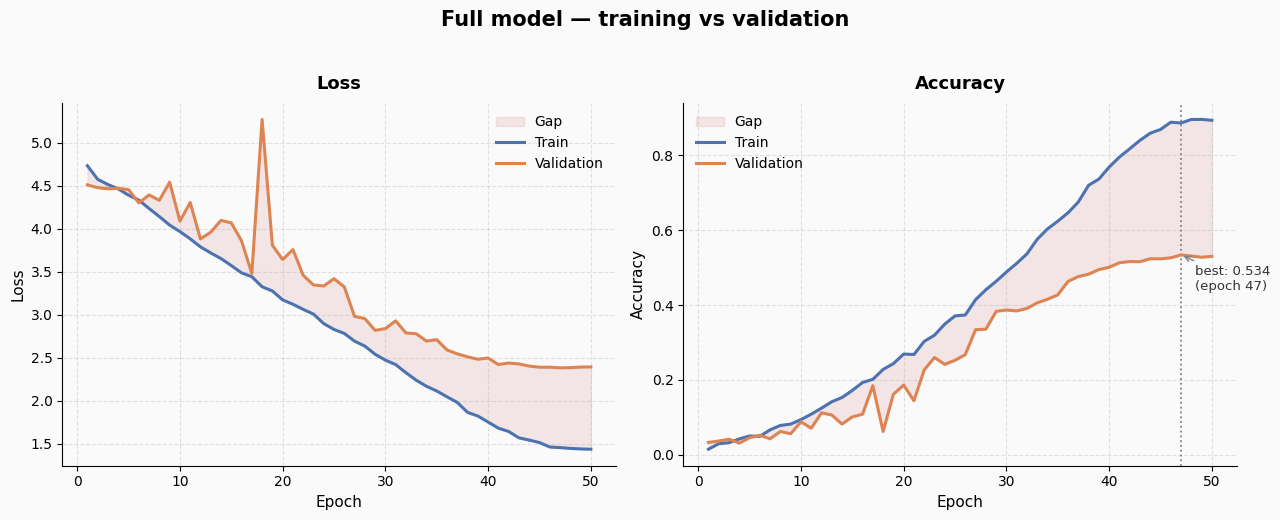

In [ ]:
# training vs validation curves for the full model
best_epoch_idx = int(np.argmax(history["val_acc"]))
best_val = history["val_acc"][best_epoch_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor="#FAFAFA")

train_color, val_color, gap_color = "#4C72B0", "#DD8452", "#C44E52"

for ax, train_key, val_key, ylabel, title in [
    (axes[0], "train_loss", "val_loss", "Loss", "Loss"),
    (axes[1], "train_acc", "val_acc", "Accuracy", "Accuracy"),
]:
    epochs = range(1, len(history[train_key]) + 1)
    ax.set_facecolor("#FAFAFA")
    ax.fill_between(epochs, history[train_key], history[val_key],
                     color=gap_color, alpha=0.12, label="Gap", zorder=1)
    ax.plot(epochs, history[train_key], label="Train", color=train_color, linewidth=2.2, zorder=3)
    ax.plot(epochs, history[val_key], label="Validation", color=val_color, linewidth=2.2, zorder=3)
    ax.set_xlabel("Epoch", fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight="bold", pad=10)
    ax.grid(True, linestyle="--", alpha=0.35, zorder=0)
    ax.legend(frameon=False, fontsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# mark the best validation epoch on the accuracy panel
axes[1].axvline(best_epoch_idx + 1, color="gray", linestyle=":", linewidth=1.3, zorder=2)
axes[1].annotate(f"best: {best_val:.3f}\n(epoch {best_epoch_idx + 1})",
                  xy=(best_epoch_idx + 1, best_val), xytext=(10, -25),
                  textcoords="offset points", fontsize=9.5, color="#333333",
                  arrowprops=dict(arrowstyle="->", color="gray", lw=1))

fig.suptitle("Full model — training vs validation", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

The plot above shows the train/validation gap directly. Both curves improve together, but training accuracy climbs faster and ends at ~89%, while validation accuracy reaches ~53%: a gap of about 36 percentage points. The gap opens in the middle of training and widens as the learning rate falls. Validation accuracy only stops improving in the last epochs, when the learning rate is close to zero, and the validation loss flattens around 2.39 at the same point. This is the overfitting that the ablation study below is meant to explain, one component at a time.

### Test-set evaluation

Now let's evaluate the test set to obtain an unbiased estimate of how the final model performs on data it never influenced in any way.

In [ ]:
# the test set is never used for design decisions: it is evaluated here for the final model, and later for every run only for completeness
best_full_model_state = all_experiments["full_model"]["best_state"]

model_test = AircraftCNN(n_classes, use_bn=True, use_gap=True, extra_block=True, dropout_p=0.5).to(device)
model_test.load_state_dict(best_full_model_state)

# plain cross-entropy (no label smoothing) here, so the reported loss is directly comparable to a standard classification loss
test_criterion = nn.CrossEntropyLoss()
test_loss, test_acc = evaluate(model_test, loader_test, test_criterion, device)

print(f"Final model \u2014 test loss: {test_loss:.4f} | test accuracy: {test_acc:.4f}")


  0%|          | 0/53 [00:00<?, ?it/s]

Final model — test loss: 1.8496 | test accuracy: 0.5236


**Result:** the full model reaches a best validation accuracy of **53.41%** (epoch 47 of 50), with a final training accuracy of 89.38%. On the test set, evaluated once right after this training run, it reaches **52.36%**: close to the validation accuracy and slightly below it, which is the expected direction given that every design choice was tuned by looking only at validation.

## Ablation study

Starting from the final model configuration, each experiment below removes **one** component and re-trains from scratch with everything else unchanged, so that the accuracy drop can be attributed to that component. The only exception is Experiment 3, which removes Global Average Pooling and the 5th convolutional block together, because during development the two only helped as a pair (see its discussion).

The seven ablations span two kinds of design choices: *architectural* ones (Batch Normalization, Global Average Pooling with the 5th convolutional block) and *training-recipe* ones (data augmentation, weight decay, Dropout, label smoothing, the learning-rate scheduler). Batch Normalization sits at the boundary between the two: it is an architectural layer, but its main observed effect is on training stability rather than on representational capacity.

### Experiment 1 - Remove Batch Normalization

In [ ]:
fix_random(42)
model_no_bn = AircraftCNN(n_classes, use_bn=False, use_gap=True, extra_block=True, dropout_p=0.5).to(device)
history, state, acc = run_experiment(
    model_no_bn, loader_train_final, loader_val_fast, num_epochs=50,
    scheduler_type="onecycle", max_lr=3e-3, weight_decay=1e-3, label_smoothing=0.1,
    run_name="no_batchnorm"
)


Found saved results for 'no_batchnorm' — replaying epoch log:

Epoch 1/50 | train_loss=4.6079 train_acc=0.0066 | val_loss=4.6048 val_acc=0.0099 | lr=0.000152
Epoch 2/50 | train_loss=4.6047 train_acc=0.0129 | val_loss=4.6019 val_acc=0.0189 | lr=0.000245
Epoch 3/50 | train_loss=4.5934 train_acc=0.0156 | val_loss=4.5824 val_acc=0.0135 | lr=0.000396
Epoch 4/50 | train_loss=4.5658 train_acc=0.0159 | val_loss=4.5691 val_acc=0.0147 | lr=0.000598
Epoch 5/50 | train_loss=4.5568 train_acc=0.0159 | val_loss=4.5560 val_acc=0.0171 | lr=0.000842
Epoch 6/50 | train_loss=4.5414 train_acc=0.0189 | val_loss=4.5316 val_acc=0.0222 | lr=0.001117
Epoch 7/50 | train_loss=4.5237 train_acc=0.0213 | val_loss=4.5066 val_acc=0.0237 | lr=0.001412
Epoch 8/50 | train_loss=4.5334 train_acc=0.0207 | val_loss=4.5157 val_acc=0.0282 | lr=0.001714
Epoch 9/50 | train_loss=4.5059 train_acc=0.0243 | val_loss=4.5218 val_acc=0.0255 | lr=0.002008
Epoch 10/50 | train_loss=4.4951 train_acc=0.0270 | val_loss=4.4961 val_acc=0.0309 

**Result:** removing Batch Normalization causes a large drop in accuracy, to **19.32%** (epoch 44).

Batch Normalization normalizes the activations produced by each convolutional block, for every batch, throughout training. Without it, the distribution of activations at each layer can drift as the weights update, making the optimization landscape harder to navigate; this is consistent with training accuracy reaching only 19.4% by epoch 50, essentially matching validation accuracy the whole way through. Without Batch Normalization the network is not overfitting: it is struggling to learn the training set at all.

### Experiment 2 - Remove data augmentation

In [ ]:
fix_random(42)
model_no_aug = AircraftCNN(n_classes, use_bn=True, use_gap=True, extra_block=True, dropout_p=0.5).to(device)
history, state, acc = run_experiment(
    model_no_aug, loader_train_base, loader_val_fast, num_epochs=50,
    scheduler_type="onecycle", max_lr=3e-3, weight_decay=1e-3, label_smoothing=0.1,
    run_name="no_augmentation"
)


Found saved results for 'no_augmentation' — replaying epoch log:

Epoch 1/50 | train_loss=4.6863 train_acc=0.0174 | val_loss=4.4820 val_acc=0.0279 | lr=0.000152
Epoch 2/50 | train_loss=4.4937 train_acc=0.0366 | val_loss=4.4259 val_acc=0.0465 | lr=0.000245
Epoch 3/50 | train_loss=4.4037 train_acc=0.0486 | val_loss=4.3701 val_acc=0.0657 | lr=0.000396
Epoch 4/50 | train_loss=4.3274 train_acc=0.0582 | val_loss=4.3612 val_acc=0.0546 | lr=0.000598
Epoch 5/50 | train_loss=4.2143 train_acc=0.0756 | val_loss=4.5611 val_acc=0.0321 | lr=0.000842
Epoch 6/50 | train_loss=4.1129 train_acc=0.0825 | val_loss=4.1729 val_acc=0.0714 | lr=0.001117
Epoch 7/50 | train_loss=3.9619 train_acc=0.1014 | val_loss=4.7749 val_acc=0.0333 | lr=0.001412
Epoch 8/50 | train_loss=3.8398 train_acc=0.1338 | val_loss=4.2315 val_acc=0.0690 | lr=0.001714
Epoch 9/50 | train_loss=3.7683 train_acc=0.1329 | val_loss=4.3713 val_acc=0.0669 | lr=0.002008
Epoch 10/50 | train_loss=3.6741 train_acc=0.1497 | val_loss=4.2635 val_acc=0.08

**Result:** removing data augmentation lowers best validation accuracy to **45.75%** (epoch 48).

The effect on overfitting, however, is much larger: training accuracy reaches **100%** by epoch 43 and stays there for the rest of training, while validation accuracy plateaus around 45%.
With only about 33 images per class and no artificial variation added to them, the network has little difficulty memorizing the entire training set exactly, while learning comparatively little that transfers to unseen images.

### Experiment 3 - Remove Global Average Pooling and the 5th convolutional block

In [ ]:
fix_random(42)
model_no_gap = AircraftCNN(n_classes, use_bn=True, use_gap=False, extra_block=False, dropout_p=0.5).to(device)
history, state, acc = run_experiment(
    model_no_gap, loader_train_final, loader_val_fast, num_epochs=50,
    scheduler_type="onecycle", max_lr=3e-3, weight_decay=1e-3, label_smoothing=0.1,
    run_name="no_gap_and_extra_block"
)


Found saved results for 'no_gap_and_extra_block' — replaying epoch log:

Epoch 1/50 | train_loss=5.1277 train_acc=0.0240 | val_loss=4.5688 val_acc=0.0438 | lr=0.000152
Epoch 2/50 | train_loss=4.5940 train_acc=0.0510 | val_loss=4.4788 val_acc=0.0558 | lr=0.000245
Epoch 3/50 | train_loss=4.5380 train_acc=0.0900 | val_loss=4.5256 val_acc=0.0723 | lr=0.000396
Epoch 4/50 | train_loss=4.5641 train_acc=0.0921 | val_loss=4.8736 val_acc=0.0816 | lr=0.000598
Epoch 5/50 | train_loss=4.4169 train_acc=0.1131 | val_loss=4.3596 val_acc=0.1029 | lr=0.000842
Epoch 6/50 | train_loss=4.1540 train_acc=0.1380 | val_loss=4.1399 val_acc=0.1239 | lr=0.001117
Epoch 7/50 | train_loss=3.8256 train_acc=0.1776 | val_loss=4.0138 val_acc=0.1428 | lr=0.001412
Epoch 8/50 | train_loss=3.6328 train_acc=0.2184 | val_loss=3.9363 val_acc=0.1647 | lr=0.001714
Epoch 9/50 | train_loss=3.5767 train_acc=0.2331 | val_loss=4.1824 val_acc=0.1377 | lr=0.002008
Epoch 10/50 | train_loss=3.4009 train_acc=0.2606 | val_loss=3.6957 val_a

**Result:** reverting to this configuration lowers best validation accuracy to **49.08%** (epoch 40), against 53.41% for the full model. The difference in training behaviour is larger: training accuracy reaches 98.5% by epoch 50, the final train/validation gap grows from about 36 to about 50 percentage points, and validation accuracy peaks earlier (epoch 40 against 47).

GAP and the 5th block are removed together, rather than one at a time, because during development the two only helped as a pair: GAP alone discarded spatial information the network needed, and only the added depth compensated for that loss. Without GAP, the classifier is much larger (about 1.8M parameters instead of about 51k), and this extra capacity is mostly spent on memorizing the training set, as the wider gap shows. Since the two components were not ablated separately, this experiment measures only their joint contribution, not that of depth or pooling alone.

### Experiment 4 - Remove weight decay

In [ ]:
fix_random(42)
model_no_wd = AircraftCNN(n_classes, use_bn=True, use_gap=True, extra_block=True, dropout_p=0.5).to(device)
history, state, acc = run_experiment(
    model_no_wd, loader_train_final, loader_val_fast, num_epochs=50,
    scheduler_type="onecycle", max_lr=3e-3, weight_decay=0.0, label_smoothing=0.1,
    run_name="no_weight_decay"
)


Found saved results for 'no_weight_decay' — replaying epoch log:

Epoch 1/50 | train_loss=4.7329 train_acc=0.0156 | val_loss=4.5104 val_acc=0.0336 | lr=0.000152
Epoch 2/50 | train_loss=4.5756 train_acc=0.0294 | val_loss=4.4766 val_acc=0.0390 | lr=0.000245
Epoch 3/50 | train_loss=4.5142 train_acc=0.0336 | val_loss=4.4724 val_acc=0.0363 | lr=0.000396
Epoch 4/50 | train_loss=4.4647 train_acc=0.0417 | val_loss=4.4550 val_acc=0.0390 | lr=0.000598
Epoch 5/50 | train_loss=4.3970 train_acc=0.0531 | val_loss=4.4522 val_acc=0.0423 | lr=0.000842
Epoch 6/50 | train_loss=4.3323 train_acc=0.0474 | val_loss=4.3181 val_acc=0.0513 | lr=0.001117
Epoch 7/50 | train_loss=4.2403 train_acc=0.0660 | val_loss=4.4706 val_acc=0.0399 | lr=0.001412
Epoch 8/50 | train_loss=4.1414 train_acc=0.0807 | val_loss=4.3035 val_acc=0.0630 | lr=0.001714
Epoch 9/50 | train_loss=4.0387 train_acc=0.0879 | val_loss=4.9019 val_acc=0.0609 | lr=0.002008
Epoch 10/50 | train_loss=3.9434 train_acc=0.1071 | val_loss=4.0396 val_acc=0.10

**Result:** removing weight decay lowers the best validation accuracy to **48.48%** (epoch 46), a drop of 4.9 percentage points.

Weight decay (implemented here by Adam as an L2 penalty on the weights) is usually introduced as a regularizer, since it pushes the weights towards smaller values. If that were its main effect here, removing it would raise the training accuracy and widen the train/validation gap. Instead, the training accuracy is *lower* without weight decay (86.50% against 89.38%), and the validation accuracy falls even more, so the final gap widens only slightly (38.4 against 36.4). Weight decay therefore improves training and validation accuracy together, which suggests an effect on optimization rather than on overfitting.

A possible explanation is the presence of Batch Normalization after every convolution: the output of these layers does not depend on the scale of their weights, so weight decay cannot limit what the network represents; instead, by keeping the weights small, it keeps the effective size of the updates large.

### Experiment 5 - Remove Dropout

In [ ]:
fix_random(42)
model_no_dropout = AircraftCNN(n_classes, use_bn=True, use_gap=True, extra_block=True, dropout_p=0.0).to(device)
history, state, acc = run_experiment(
    model_no_dropout, loader_train_final, loader_val_fast, num_epochs=50,
    scheduler_type="onecycle", max_lr=3e-3, weight_decay=1e-3, label_smoothing=0.1,
    run_name="no_dropout"
)


Found saved results for 'no_dropout' — replaying epoch log:

Epoch 1/50 | train_loss=4.6011 train_acc=0.0252 | val_loss=4.4885 val_acc=0.0396 | lr=0.000152
Epoch 2/50 | train_loss=4.4313 train_acc=0.0402 | val_loss=4.4508 val_acc=0.0348 | lr=0.000245
Epoch 3/50 | train_loss=4.3505 train_acc=0.0531 | val_loss=4.4070 val_acc=0.0483 | lr=0.000396
Epoch 4/50 | train_loss=4.2740 train_acc=0.0615 | val_loss=4.4342 val_acc=0.0453 | lr=0.000598
Epoch 5/50 | train_loss=4.1592 train_acc=0.0849 | val_loss=4.3710 val_acc=0.0534 | lr=0.000842
Epoch 6/50 | train_loss=4.0474 train_acc=0.0957 | val_loss=4.3645 val_acc=0.0690 | lr=0.001117
Epoch 7/50 | train_loss=3.9048 train_acc=0.1251 | val_loss=4.3748 val_acc=0.0684 | lr=0.001412
Epoch 8/50 | train_loss=3.8161 train_acc=0.1392 | val_loss=5.5105 val_acc=0.0375 | lr=0.001714
Epoch 9/50 | train_loss=3.7400 train_acc=0.1557 | val_loss=4.5201 val_acc=0.0759 | lr=0.002008
Epoch 10/50 | train_loss=3.6321 train_acc=0.1728 | val_loss=3.8634 val_acc=0.1224 | 

**Result:** removing Dropout leaves best validation accuracy essentially unchanged, **53.68%** (epoch 46), a fraction of a point above the full model's 53.41%.

This does not mean Dropout has no effect: training accuracy reaches 99.25% by epoch 50 (versus 89.38% for the full model), and the train/validation gap widens by about 10 percentage points without it. Dropout randomly deactivates a fraction of the classifier's units at every step, preventing the network from relying too heavily on any single feature, exactly the effect visible in that narrower gap.

### Experiment 6 - Remove the learning-rate scheduler

In [ ]:
fix_random(42)
model_no_sched = AircraftCNN(n_classes, use_bn=True, use_gap=True, extra_block=True, dropout_p=0.5).to(device)
history, state, acc = run_experiment(
    model_no_sched, loader_train_final, loader_val_fast, num_epochs=50,
    lr=1e-3, scheduler_type="none", weight_decay=1e-3, label_smoothing=0.1,
    run_name="no_scheduler"
)


Found saved results for 'no_scheduler' — replaying epoch log:

Epoch 1/50 | train_loss=4.7292 train_acc=0.0156 | val_loss=4.5448 val_acc=0.0288 | lr=0.001000
Epoch 2/50 | train_loss=4.5637 train_acc=0.0183 | val_loss=4.4806 val_acc=0.0321 | lr=0.001000
Epoch 3/50 | train_loss=4.4951 train_acc=0.0327 | val_loss=4.4541 val_acc=0.0393 | lr=0.001000
Epoch 4/50 | train_loss=4.4286 train_acc=0.0450 | val_loss=4.3775 val_acc=0.0498 | lr=0.001000
Epoch 5/50 | train_loss=4.3297 train_acc=0.0531 | val_loss=4.4794 val_acc=0.0435 | lr=0.001000
Epoch 6/50 | train_loss=4.2269 train_acc=0.0606 | val_loss=4.1944 val_acc=0.0633 | lr=0.001000
Epoch 7/50 | train_loss=4.1110 train_acc=0.0738 | val_loss=4.4130 val_acc=0.0495 | lr=0.001000
Epoch 8/50 | train_loss=4.0243 train_acc=0.0936 | val_loss=3.9959 val_acc=0.0855 | lr=0.001000
Epoch 9/50 | train_loss=3.9245 train_acc=0.1017 | val_loss=3.8760 val_acc=0.1173 | lr=0.001000
Epoch 10/50 | train_loss=3.8262 train_acc=0.1218 | val_loss=3.9002 val_acc=0.1107 

**Result:** with a constant learning rate, best validation accuracy drops to **45.39%** (epoch 48).

A scheduler's role is to take large steps early in training, when the model is far from any good solution, and progressively smaller ones as it gets close. Without it, the same step size used at the start is still being taken fifty epochs later, well past the point where such large updates are useful. This is directly visible in the second half of this run: from epoch 43 onward, validation accuracy swings repeatedly between roughly 38% and 45% with no clear upward trend, instead of settling as it does in every scheduled experiment in this study. Training accuracy is also noticeably lower than the full model's (74.4% versus 89.4%) because without the fine-grained updates a shrinking learning rate provides, the model has made less overall progress by epoch 50, not just a less stable one.

### Experiment 7 - Remove label smoothing


In [ ]:
fix_random(42)
model_no_ls = AircraftCNN(n_classes, use_bn=True, use_gap=True, extra_block=True, dropout_p=0.5).to(device)
history_no_ls, state_no_ls, acc_no_ls = run_experiment(
    model_no_ls, loader_train_final, loader_val_fast, num_epochs=50,
    scheduler_type="onecycle", max_lr=3e-3, weight_decay=1e-3, label_smoothing=0.0,
    run_name="no_label_smoothing"
)

Found saved results for 'no_label_smoothing' — replaying epoch log:

Epoch 1/50 | train_loss=4.7297 train_acc=0.0156 | val_loss=4.4917 val_acc=0.0345 | lr=0.000152
Epoch 2/50 | train_loss=4.5523 train_acc=0.0288 | val_loss=4.4471 val_acc=0.0363 | lr=0.000245
Epoch 3/50 | train_loss=4.4826 train_acc=0.0351 | val_loss=4.4307 val_acc=0.0417 | lr=0.000396
Epoch 4/50 | train_loss=4.4198 train_acc=0.0432 | val_loss=4.4031 val_acc=0.0372 | lr=0.000598
Epoch 5/50 | train_loss=4.3413 train_acc=0.0516 | val_loss=4.3514 val_acc=0.0495 | lr=0.000842
Epoch 6/50 | train_loss=4.2514 train_acc=0.0492 | val_loss=4.2245 val_acc=0.0474 | lr=0.001117
Epoch 7/50 | train_loss=4.1348 train_acc=0.0708 | val_loss=4.3258 val_acc=0.0480 | lr=0.001412
Epoch 8/50 | train_loss=4.0145 train_acc=0.0786 | val_loss=4.3564 val_acc=0.0576 | lr=0.001714
Epoch 9/50 | train_loss=3.9066 train_acc=0.0870 | val_loss=4.3143 val_acc=0.0699 | lr=0.002008
Epoch 10/50 | train_loss=3.7793 train_acc=0.0975 | val_loss=3.9258 val_acc=0

**Result:** without label smoothing, best validation accuracy is **52.81%** (epoch 47), against 53.41% for the full model. The 0.6-point difference is smaller than the noise of a 3333-image validation set, so this experiment cannot tell whether label smoothing helps or not. The train/validation gap is also unchanged (final training accuracy 88.7% versus 89.4% with it): with only ~33 images per class, the network's overfitting is driven mainly by the other components studied above, and smoothing the targets adds little on top of them.

Label smoothing is kept in the final model as a standard, cost-free regularizer, but, like Dropout, its measurable contribution to accuracy is negligible in this ablation.

### Summary and Test-set accuracy for every configuration

The table and plot below collect the full model and every ablation run above. Since every experiment removes one component from the full model, the accuracy difference between "Full model" and any other row directly quantifies that component's contribution.

In [ ]:
ablation_configs = {
    "full_model":               dict(use_bn=True,  use_gap=True,  extra_block=True,  dropout_p=0.5),
    "no_batchnorm":              dict(use_bn=False, use_gap=True,  extra_block=True,  dropout_p=0.5),
    "no_augmentation":           dict(use_bn=True,  use_gap=True,  extra_block=True,  dropout_p=0.5),
    "no_gap_and_extra_block":    dict(use_bn=True,  use_gap=False, extra_block=False, dropout_p=0.5),
    "no_weight_decay":           dict(use_bn=True,  use_gap=True,  extra_block=True,  dropout_p=0.5),
    "no_dropout":                dict(use_bn=True,  use_gap=True,  extra_block=True,  dropout_p=0.0),
    "no_scheduler":              dict(use_bn=True,  use_gap=True,  extra_block=True,  dropout_p=0.5),
    "no_label_smoothing":        dict(use_bn=True, use_gap=True, extra_block=True, dropout_p=0.5)
}

  0%|          | 0/53 [00:00<?, ?it/s]

  0%|          | 0/53 [00:00<?, ?it/s]

  0%|          | 0/53 [00:00<?, ?it/s]

  0%|          | 0/53 [00:00<?, ?it/s]

  0%|          | 0/53 [00:00<?, ?it/s]

  0%|          | 0/53 [00:00<?, ?it/s]

  0%|          | 0/53 [00:00<?, ?it/s]

  0%|          | 0/53 [00:00<?, ?it/s]

,Validation acc. (%),Δ vs full model (pp),Test acc. (%)
Experiment,,,
full model,53.41,-,52.36
no batchnorm,19.32,-34.08,19.44
no augmentation,45.75,-7.65,47.10
no gap and extra block,49.08,-4.32,48.30
no weight decay,48.48,-4.92,48.90
no dropout,53.68,+0.27,52.48
no scheduler,45.39,-8.01,42.69
no label smoothing,52.81,-0.60,51.19


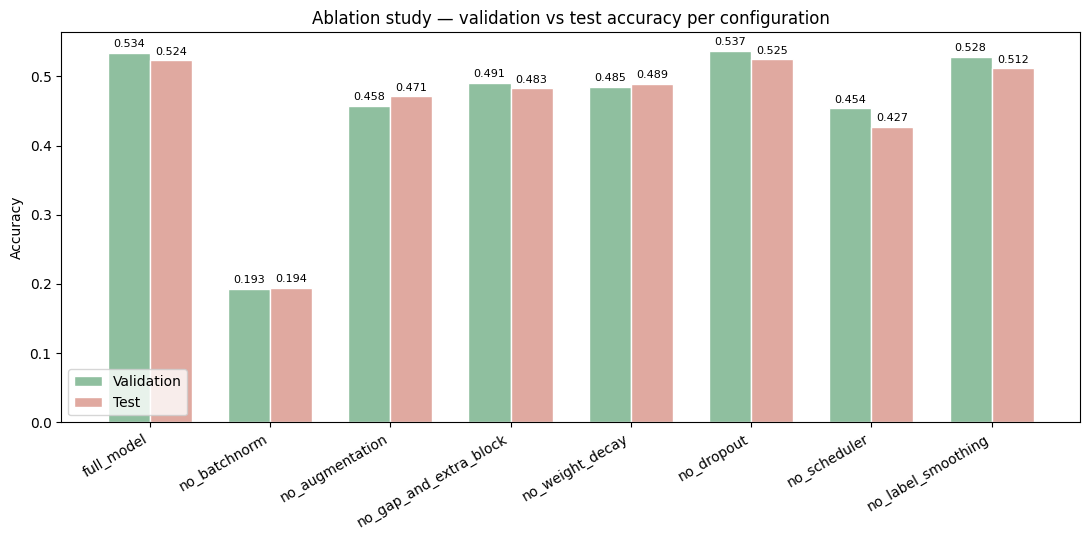

In [ ]:
# val vs test accuracy for every ablation configuration
test_criterion = nn.CrossEntropyLoss()

# only the Part 1 ablation runs (all_experiments also holds the Part 2 runs)
names = [n for n in all_experiments if n in ablation_configs]
val_accs = [all_experiments[n]["best_acc"] for n in names]
test_accs = []

for name in names:
    model_eval = AircraftCNN(n_classes, **ablation_configs[name]).to(device)
    model_eval.load_state_dict(all_experiments[name]["best_state"])
    _, test_acc = evaluate(model_eval, loader_test, test_criterion, device)
    test_accs.append(test_acc)

baseline_val = all_experiments["full_model"]["best_acc"]

# summary table (accuracies in %, delta in percentage points)
df = pd.DataFrame({
    "Experiment": [n.replace("_", " ") for n in names],
    "Validation acc. (%)": [100 * v for v in val_accs],
    "Δ vs full model (pp)": [100 * (v - baseline_val) for v in val_accs],
    "Test acc. (%)": [100 * t for t in test_accs],
}).set_index("Experiment")

display(df.style
        .format({"Validation acc. (%)": "{:.2f}",
                 "Δ vs full model (pp)": lambda d: "-" if d == 0 else f"{d:+.2f}",
                 "Test acc. (%)": "{:.2f}"})
        .highlight_max(subset=["Validation acc. (%)", "Test acc. (%)"],
                       props="font-weight: bold; background-color: #DDEBF7;")
        .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}]))

# grouped bar chart: validation vs test accuracy, side by side, for every configuration
x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(x - width/2, val_accs, width, label="Validation", color="#8FBF9F", edgecolor="white")
ax.bar(x + width/2, test_accs, width, label="Test", color="#E0A9A0", edgecolor="white")

for i, (v, t) in enumerate(zip(val_accs, test_accs)):
    ax.text(i - width/2, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.text(i + width/2, t + 0.005, f"{t:.3f}", ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_ylabel("Accuracy")
ax.set_title("Ablation study — validation vs test accuracy per configuration")
ax.legend()
plt.tight_layout()
plt.show()

## Final considerations

The final network reaches **53.41%** validation accuracy and **52.36%** on the test set, above the **~50%** target. The gap between the two is about one percentage point, of the same size as the standard error of a 3333-image split (about ±0.9 pp), and consistent with every design choice having been made on validation data only.

The ablation study shows that the components do not contribute equally. The values below are the change in validation accuracy, in percentage points, when each component is removed. **Batch Normalization** is by far the most important (−34.1 pp; without it the network barely learns the training set). It is followed by the **learning-rate scheduler** (−8.0 pp), **data augmentation** (−7.7 pp), **weight decay** (−4.9 pp) and the pair formed by **Global Average Pooling and the 5th block** (−4.3 pp). **Label smoothing** (−0.6 pp) and **Dropout** (+0.3 pp) have no measurable effect on accuracy, since both differences are smaller than the noise of the validation set. Dropout does, however, narrow the train/validation gap by about 10 pp, so it changes how the network fits the training set without changing how well it generalizes. The test set confirms the same three groups (large, medium, negligible); the small changes in ranking within each group are within the noise for differences of this size.

The training accuracies also show that the components act in two different ways. Batch Normalization, the scheduler and weight decay mainly help **optimization**: removing any of them lowers training *and* validation accuracy together. Augmentation, GAP with the extra block, and Dropout mainly fight **overfitting**: removing them leaves training accuracy equal or higher (up to 100% without augmentation), while validation accuracy drops or stays the same, so the gap widens. Label smoothing has no clear effect in either direction. Since every ablation removes one component while all the others stay active, components that partly overlap in what they correct for (such as Dropout and label smoothing, on top of augmentation) may be under-credited by their isolated drop.

Even in the final model, overfitting is not eliminated: training accuracy reaches ~89% against ~53% on validation. With about 33 images per class, a network trained from scratch has little to learn beyond what it can memorize, and regularization narrows this gap but cannot close it. All results come from a single training run per configuration (seed 42), so differences below about two percentage points should be read as inconclusive. This limitation of training from scratch is what Part 2 addresses from a different angle, by starting from weights that already encode general visual knowledge.

# Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `FGVCAircraft`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~70%.

## Summary of the approach

Fine-tuning started from the ImageNet-pretrained ResNet-18 with the hyperparameters of Part 1 (2A), which already gave 77.44% on the test set. The training curves showed two problems: an unstable first half of training, caused by a learning rate tuned for a network without pretrained weights, and overfitting. Section 2B addresses them following the course recommendations on fine-tuning:

- a **uniform lower learning rate** was tested first, and it lowered the accuracy (Attempt 1);
- **layer-wise learning rates**, small for the generic lower layers and large for the new classifier, recovered the drop of Attempt 1 (Attempt 2);
- **gradual unfreezing**, training the classifier first and then the other layers from the top down, gave a small further gain on validation (Attempt 3);
- a **higher input resolution** (256×384) gave the clearest improvement.

The final solution combines the last three and reaches **80.83%** on the test set, above the ~70% target. Section 2B.1 presents it, and 2B.2 reports the attempts that led to it.

## Preprocessing

Since ResNet-18 is pretrained on ImageNet, its input must be normalized with ImageNet's own per-channel statistics. However, the usual `Resize(224) + CenterCrop(224)` pipeline is not used: FGVC-Aircraft images have an aspect ratio of about 1.5, so a square center crop would discard roughly a third of the width, where wingtips, tail and engines often lie, and these are details that can separate neighbouring variants. Images are instead resized to 224×320 (aspect ratio ≈ 1.43) with no cropping. This is possible because ResNet-18 ends with an adaptive average pooling, so it accepts any input size, and it is consistent with Part 1, where the full image was also kept (112×160).

The copyright-banner crop is still applied, since it is a property of the dataset, not of the network. The augmentation found to work best in Part 1 (flip, rotation, color jitter, random erasing) is reused here.

In [ ]:
# Standard ImageNet per-channel statistics
mean_imagenet = [0.485, 0.456, 0.406]
std_imagenet = [0.229, 0.224, 0.225]

resnet_img_height, resnet_img_width = 224, 320  # rectangular, aspect ratio ~1.43

# Same transformation as above but with different Normalization
data_transforms_resnet = {
    "train_aug": T.Compose([
        T.Lambda(crop_copyright_banner),
        T.Resize((resnet_img_height, resnet_img_width)),
        T.RandomHorizontalFlip(),
        T.RandomRotation(degrees=10),
        T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        T.ToTensor(),
        T.Normalize(mean_imagenet, std_imagenet),
        T.RandomErasing(p=0.3, scale=(0.02, 0.1))
    ]),
    "test": T.Compose([
        T.Lambda(crop_copyright_banner),
        T.Resize((resnet_img_height, resnet_img_width)),
        T.ToTensor(),
        T.Normalize(mean_imagenet, std_imagenet)
    ])
}

data_train_resnet_aug = FGVCAircraft(
    root="/data/", split="train", annotation_level="variant",
    transform=data_transforms_resnet["train_aug"], download=True
)
data_val_resnet = FGVCAircraft(
    root="/data/", split="val", annotation_level="variant",
    transform=data_transforms_resnet["test"], download=True
)
data_test_resnet = FGVCAircraft(
    root="/data/", split="test", annotation_level="variant",
    transform=data_transforms_resnet["test"], download=True
)

# batch size halved with respect to Part 1 because this configuration needs more GPU
loader_train_resnet_aug = DataLoader(data_train_resnet_aug, batch_size=32, shuffle=True, pin_memory=True)
loader_val_resnet = DataLoader(data_val_resnet, batch_size=32, shuffle=False, pin_memory=True)
loader_test_resnet = DataLoader(data_test_resnet, batch_size=32, shuffle=False, pin_memory=True)


### Loading the pretrained network

The final classification layer is replaced to output `n_classes` scores instead of the original 1000 (ImageNet classes).

In [ ]:
fix_random(42)
weights = ResNet18_Weights.IMAGENET1K_V1
model_resnet = resnet18(weights=weights)
model_resnet.fc = nn.Linear(model_resnet.fc.in_features, n_classes)
model_resnet = model_resnet.to(device)
summary(model_resnet, input_size=(3, resnet_img_height, resnet_img_width))


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 141MB/s]


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 160]           9,408
       BatchNorm2d-2         [-1, 64, 112, 160]             128
              ReLU-3         [-1, 64, 112, 160]               0
         MaxPool2d-4           [-1, 64, 56, 80]               0
            Conv2d-5           [-1, 64, 56, 80]          36,864
       BatchNorm2d-6           [-1, 64, 56, 80]             128
              ReLU-7           [-1, 64, 56, 80]               0
            Conv2d-8           [-1, 64, 56, 80]          36,864
       BatchNorm2d-9           [-1, 64, 56, 80]             128
             ReLU-10           [-1, 64, 56, 80]               0
       BasicBlock-11           [-1, 64, 56, 80]               0
           Conv2d-12           [-1, 64, 56, 80]          36,864
      BatchNorm2d-13           [-1, 64, 56, 80]             128
             ReLU-14           [-1, 64,

### 2A - Fine-tuning with Part 1's hyperparameters

As required, the optimization hyperparameters of the final Part 1 model (Adam, OneCycle schedule with `max_lr=3e-3`, weight decay `1e-3`, label smoothing `0.1`, 50 epochs) are reused unchanged. Besides the network itself and the input pipeline (rectangular 224×320 images normalized with ImageNet statistics), the only training hyperparameter that differs is the batch size, halved from 64 to 32 to fit the larger images in GPU memory. Since OneCycle is defined over the total number of steps, the per-epoch learning-rate schedule is the same as in Part 1 (peak at epoch 15); the network simply takes twice as many steps per epoch, each on a smaller batch.

In [ ]:
history_2a, state_2a, acc_2a = run_experiment(
    model_resnet, loader_train_resnet_aug, loader_val_resnet, num_epochs=50,
    scheduler_type="onecycle", max_lr=3e-3, weight_decay=1e-3, label_smoothing=0.1,
    run_name="part2_2a_resnet_finetuned_50"
)


Found saved results for 'part2_2a_resnet_finetuned_50' — replaying epoch log:

Epoch 1/50 | train_loss=4.2675 train_acc=0.0948 | val_loss=3.6022 val_acc=0.1719 | lr=0.000152
Epoch 2/50 | train_loss=3.1849 train_acc=0.3437 | val_loss=2.7782 val_acc=0.3708 | lr=0.000245
Epoch 3/50 | train_loss=2.4557 train_acc=0.5156 | val_loss=2.4824 val_acc=0.4581 | lr=0.000395
Epoch 4/50 | train_loss=2.1375 train_acc=0.5960 | val_loss=2.7424 val_acc=0.3747 | lr=0.000597
Epoch 5/50 | train_loss=2.1469 train_acc=0.5696 | val_loss=2.9817 val_acc=0.3459 | lr=0.000841
Epoch 6/50 | train_loss=2.2033 train_acc=0.5348 | val_loss=3.0361 val_acc=0.3378 | lr=0.001116
Epoch 7/50 | train_loss=2.2377 train_acc=0.5279 | val_loss=3.4156 val_acc=0.3102 | lr=0.001411
Epoch 8/50 | train_loss=2.2660 train_acc=0.5291 | val_loss=3.2809 val_acc=0.3042 | lr=0.001712
Epoch 9/50 | train_loss=2.3330 train_acc=0.5060 | val_loss=4.2132 val_acc=0.1779 | lr=0.002007
Epoch 10/50 | train_loss=2.3400 train_acc=0.5024 | val_loss=3.7098

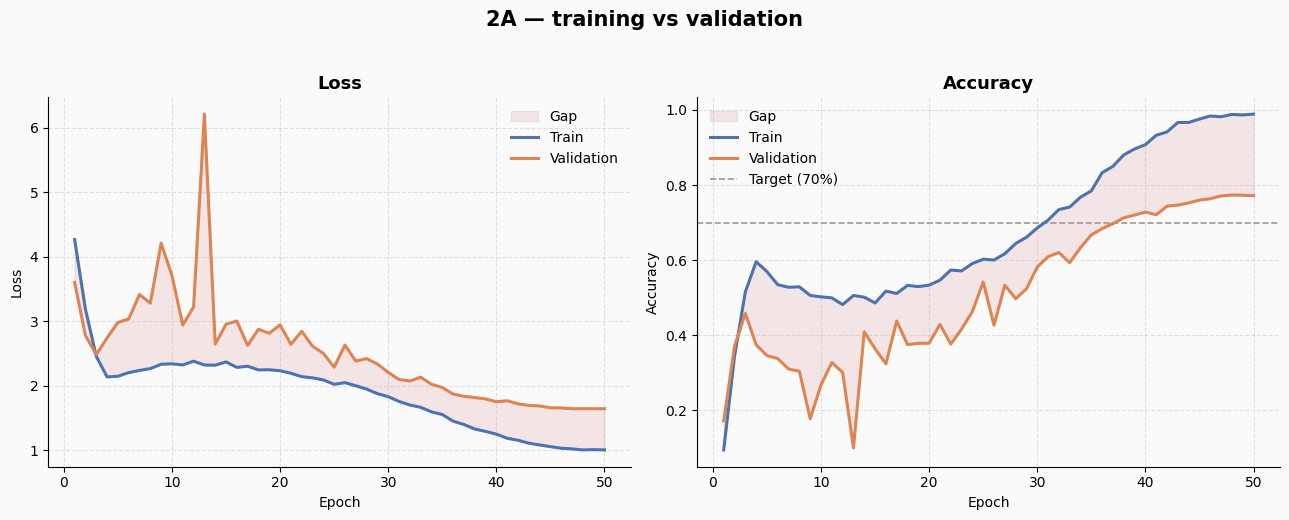

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor="#FAFAFA")
train_color, val_color, gap_color, target_color = "#4C72B0", "#DD8452", "#C44E52", "#999999"

for ax, train_key, val_key, title in [
    (axes[0], "train_loss", "val_loss", "Loss"),
    (axes[1], "train_acc", "val_acc", "Accuracy"),
]:
    epochs = range(1, len(history_2a[train_key]) + 1)
    ax.set_facecolor("#FAFAFA")
    ax.fill_between(epochs, history_2a[train_key], history_2a[val_key],
                    color=gap_color, alpha=0.12, label="Gap", zorder=1)
    ax.plot(epochs, history_2a[train_key], label="Train", color=train_color, linewidth=2.2, zorder=3)
    ax.plot(epochs, history_2a[val_key], label="Validation", color=val_color, linewidth=2.2, zorder=3)
    if title == "Accuracy":
        ax.axhline(0.70, color=target_color, linestyle="--", linewidth=1.2, label="Target (70%)")
    ax.set_xlabel("Epoch"); ax.set_ylabel(title)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

fig.suptitle("2A — training vs validation", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Result:** best validation accuracy reaches **77.35%** (epoch 48), already above the ~70% target. Training accuracy reaches ~99% (final train loss 1.00 against a validation loss of 1.64), so the model fits the training set almost perfectly. Another important thing to notice is that the first half of training is unstable. Training accuracy itself falls from 60% at epoch 4 to about 50% between epochs 10 and 15, and validation accuracy drops to 10% at epoch 13, right before the learning rate reaches its peak (`3e-3`, epoch 15): steps of that size, tuned in Part 1 for a network starting from random weights, are large enough to damage the pretrained features. Validation accuracy only starts to improve steadily from about epoch 30, once the learning rate has fallen below 2e-3.

### Test

In [ ]:
model_test_2a = resnet18(weights=None)
model_test_2a.fc = nn.Linear(model_test_2a.fc.in_features, n_classes)
model_test_2a = model_test_2a.to(device)
model_test_2a.load_state_dict(state_2a)

test_criterion = nn.CrossEntropyLoss()
test_loss_2a, test_acc_2a = evaluate(model_test_2a, loader_test_resnet, test_criterion, device)
print(f"2A — test loss: {test_loss_2a:.4f} | test accuracy: {test_acc_2a:.4f}")

  0%|          | 0/105 [00:00<?, ?it/s]

2A — test loss: 1.0240 | test accuracy: 0.7744


Evaluated once on the test set, 2A reaches **77.44%** (test loss 1.02), within 0.1 points of its validation accuracy (77.35%). The difference between validation and test is well below the standard error of a 3333-image split (about ±0.7 pp at this accuracy), so the validation accuracy is a reliable guide for the choices in 2B.

## 2B - Improving the fine-tuning

2A already exceeds the ~70% target, so the goal of 2B is to improve on 77.35% validation accuracy, using the training curves to decide what to change.

Two things stand out in the 2A plots. First, the first half of training is unstable: the training accuracy itself falls and the validation accuracy collapses to 10% while the learning rate ramps up to `3e-3`, the value tuned in Part 1 for a network with no pretrained weights to protect. Second, training accuracy reaches ~100% while validation stays lower: the network is limited by overfitting, not by optimization.

The course slides on transfer learning suggest two ways of proceeding when fine-tuning: use a smaller learning rate than in the original training, and freeze the lower layers or use progressive learning rates. We combine them into a single method (2B.1): learning rates that increase with depth (small for the first layers, large for the new classifier), plus gradual unfreezing of the layers from the top down. To improve generalization we also give the network more detail per image (higher resolution), which makes similar variants easier to tell apart. Section 2B.2 reports the simpler attempts that led to this method, adding one ingredient at a time.

### 2B.1 Final solution

The final solution follows the course recommendations on fine-tuning and adds a higher input resolution. It combines three choices.

**Layer-wise learning rates.** In a pretrained network the layers do not need to change equally: the first ones detect generic patterns such as edges and textures, which transfer well between tasks, while the last ones are specific to the original task. Adapting the "discriminative fine-tuning" of Howard & Ruder (2018), who give each layer its own learning rate, the network is split into six groups (first convolution, `layer1`–`layer4`, classifier). The classifier, which is new, uses `3e-3`, and each group below it uses half the rate of the one above, down to `9.4e-5` for the first convolution. In this way the generic lower layers are barely modified, while the upper layers can adapt to aircraft.

**Gradual unfreezing.** This is the "freeze the lower layers" recommendation of the slides, applied progressively as in Howard & Ruder (2018): training starts with only the classifier, then one more group is unfrozen every two epochs from the top down, so that all layers are training from the 11th epoch on, before the learning-rate peak at epoch 15. The reason is that the new classifier starts from random weights, and while it is still poor its large gradients would also modify the pretrained layers below it. A similar concern motivates the linear-probing-then-fine-tuning strategy of Kumar et al. (2022), who show that updating the whole network from a random classifier can distort the pretrained features.

**Higher resolution (256×384).** Neighbouring aircraft variants differ in small details (engines, windows, tail shape), and a higher resolution makes them easier to see. The network accepts larger inputs than the 224×224 images used in ImageNet pretraining because of the global average pooling before the classifier, and increasing the input resolution is one of the standard ways of improving the accuracy of a CNN, at the price of more computation (Tan & Le, 2019). 256×384 keeps the aspect ratio of the images (1.5) with sides divisible by 32. Whether this choice pays off in our case is tested directly by comparing it with the same method at 224×320 (Attempt 3).

Two functions implement it. The first builds the data loaders for a given resolution.

In [ ]:
def make_resnet_loaders(h, w, batch_size=32):
    """Train/val/test loaders at resolution h x w (same preprocessing as above)."""
    banner = T.Lambda(crop_copyright_banner)
    norm = T.Normalize(mean_imagenet, std_imagenet)
    # training: banner crop, resize to (h, w), then the usual augmentation
    train_tf = T.Compose([
        banner, T.Resize((h, w)),
        T.RandomHorizontalFlip(),
        T.RandomRotation(degrees=10),
        T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        T.ToTensor(), norm,
        T.RandomErasing(p=0.3, scale=(0.02, 0.1)),
    ])
    # validation and test: no augmentation
    eval_tf = T.Compose([banner, T.Resize((h, w)), T.ToTensor(), norm])
    ds = {s: FGVCAircraft(root="/data/", split=s, annotation_level="variant",
                          transform=(train_tf if s == "train" else eval_tf), download=True)
          for s in ["train", "val", "test"]}
    return (DataLoader(ds["train"], batch_size=batch_size, shuffle=True, pin_memory=True),
            DataLoader(ds["val"], batch_size=batch_size, shuffle=False, pin_memory=True),
            DataLoader(ds["test"], batch_size=batch_size, shuffle=False, pin_memory=True))

The second function trains ResNet-18 with the method above. The argument `unfreeze_at` maps each group (0 = first convolution, 5 = classifier) to the epoch at which it starts training; by default it is the schedule described above. The result of each run is saved under `RESULTS_DIR`, so a finished run is reloaded instead of retrained after a restart.

In [ ]:
def run_gradual_unfreeze(run_name, loader_train, loader_val, num_epochs=50,
                         unfreeze_at=None, top_lr=3e-3, decay=0.5):
    """ResNet-18 fine-tuning with layer-wise learning rates and gradual unfreezing."""
    json_path = Path(RESULTS_DIR) / f"{run_name}.json"
    pt_path = Path(RESULTS_DIR) / f"{run_name}.pt"

    # if this run was already trained and saved, load it instead of re-training
    if json_path.exists() and pt_path.exists():
        with open(json_path) as f:
            saved = json.load(f)
        best_state = torch.load(pt_path, map_location=device)
        h = saved["history"]
        for e in range(len(h["train_loss"])):
            print(f"Epoch {e+1}/{len(h['train_loss'])} | train_loss={h['train_loss'][e]:.4f} "
                  f"train_acc={h['train_acc'][e]:.4f} | val_loss={h['val_loss'][e]:.4f} "
                  f"val_acc={h['val_acc'][e]:.4f}")
        print(f"\nBest val accuracy: {saved['best_acc']:.4f} (epoch {saved['best_epoch']})")
        all_experiments[run_name] = {"history": h, "best_state": best_state, "best_acc": saved["best_acc"]}
        return h, best_state, saved["best_acc"]

    # epoch at which each group of layers starts training: the classifier (5) first, then one residual stage every two epochs, the first convolution (0) last
    if unfreeze_at is None:
        unfreeze_at = {5: 0, 4: 2, 3: 4, 2: 6, 1: 8, 0: 10}

    # pretrained ResNet-18 with a new classifier for our classes
    fix_random(42)
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, n_classes)
    model = model.to(device)

    # split the network into six groups, from the first convolution (0) to the classifier (5);
    # each group gets its own learning rate: top_lr for the classifier, and half of the rate of the group above for each group below it
    stages = [[model.conv1, model.bn1], [model.layer1], [model.layer2],
              [model.layer3], [model.layer4], [model.fc]]
    groups = [{"params": [p for m in mods for p in m.parameters()],
               "lr": top_lr * decay ** (len(stages) - 1 - i)}
              for i, mods in enumerate(stages)]

    # start with everything frozen; groups are unfrozen later by the loop below
    for p in model.parameters():
        p.requires_grad = False

    # same loss, optimizer and OneCycle schedule as 2A, but one peak rate per group
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.Adam(groups, weight_decay=1e-3)
    batch_scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[g["lr"] for g in groups], total_steps=num_epochs * len(loader_train))

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_state, best_epoch = 0.0, None, 0

    for epoch in range(num_epochs):
        # unfreeze the groups whose turn has come at this epoch
        for gi, e in unfreeze_at.items():
            if epoch == e:
                for p in groups[gi]["params"]:
                    p.requires_grad = True

        # one epoch of training and one of validation
        train_loss, train_acc = train_one_epoch(model, loader_train, optimizer, criterion, device, batch_scheduler=batch_scheduler)
        val_loss, val_acc = evaluate(model, loader_val, criterion, device)
        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        print(f"Epoch {epoch+1}/{num_epochs} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

        # keep the weights of the epoch with the best validation accuracy
        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch + 1
            best_state = copy.deepcopy(model.state_dict())

    # save history and best weights, so the run is not repeated after a restart
    print(f"\nBest val accuracy: {best_val_acc:.4f} (epoch {best_epoch})")
    Path(RESULTS_DIR).mkdir(parents=True, exist_ok=True)
    with open(json_path, "w") as f:
        json.dump({"history": history, "best_acc": best_val_acc, "best_epoch": best_epoch}, f)
    torch.save(best_state, pt_path)
    all_experiments[run_name] = {"history": history, "best_state": best_state, "best_acc": best_val_acc}
    return history, best_state, best_val_acc

In [ ]:
loader_train_hr, loader_val_hr, loader_test_hr = make_resnet_loaders(256, 384)

history_4, state_4, acc_4 = run_gradual_unfreeze(
    "part2_2b_unfreeze_256x384_50", loader_train_hr, loader_val_hr)

Epoch 1/50 | train_loss=4.6632 train_acc=0.0117 | val_loss=4.6015 val_acc=0.0198
Epoch 2/50 | train_loss=4.5720 train_acc=0.0225 | val_loss=4.5309 val_acc=0.0318
Epoch 3/50 | train_loss=4.0689 train_acc=0.1251 | val_loss=3.4782 val_acc=0.2241
Epoch 4/50 | train_loss=3.0889 train_acc=0.3491 | val_loss=2.7970 val_acc=0.3726
Epoch 5/50 | train_loss=2.4150 train_acc=0.5282 | val_loss=2.5050 val_acc=0.4545
Epoch 6/50 | train_loss=2.0290 train_acc=0.6281 | val_loss=2.3351 val_acc=0.4887
Epoch 7/50 | train_loss=1.8549 train_acc=0.6728 | val_loss=2.3047 val_acc=0.5278
Epoch 8/50 | train_loss=1.7815 train_acc=0.7028 | val_loss=2.5774 val_acc=0.4677
Epoch 9/50 | train_loss=1.7579 train_acc=0.7025 | val_loss=2.6228 val_acc=0.4752
Epoch 10/50 | train_loss=1.7068 train_acc=0.7238 | val_loss=2.4920 val_acc=0.4986
Epoch 11/50 | train_loss=1.6798 train_acc=0.7373 | val_loss=2.6540 val_acc=0.4524
Epoch 12/50 | train_loss=1.6816 train_acc=0.7361 | val_loss=2.5248 val_acc=0.4893
Epoch 13/50 | train_loss=

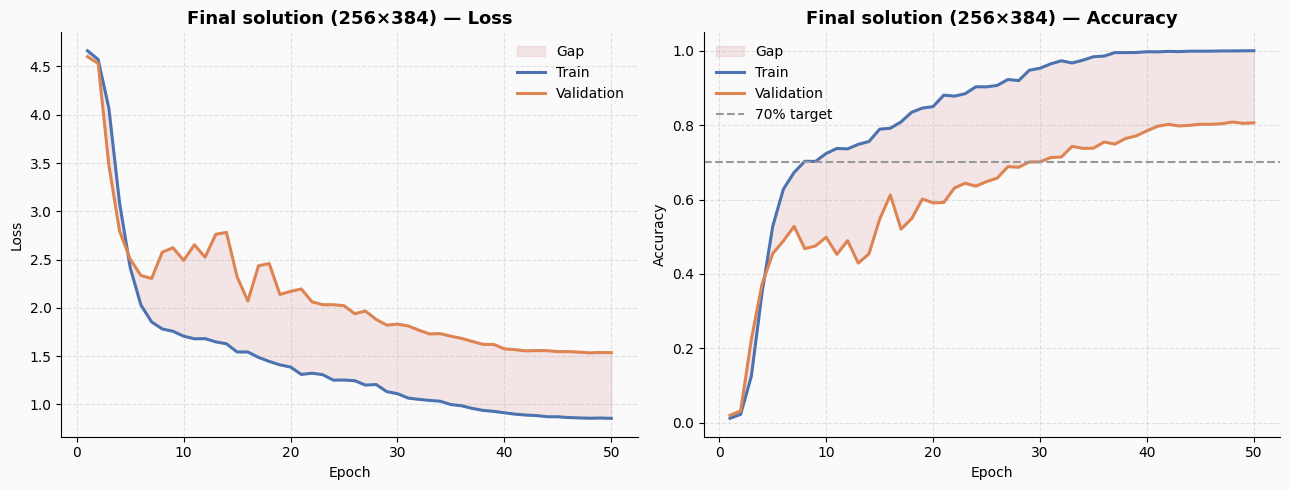

In [ ]:
def plot_history(history, title, target=0.70):
    """Train/validation loss and accuracy per epoch; the shaded area is the train-validation gap."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor="#FAFAFA")
    for ax, tk, vk, name in [(axes[0], "train_loss", "val_loss", "Loss"),
                             (axes[1], "train_acc", "val_acc", "Accuracy")]:
        ep = range(1, len(history[tk]) + 1)
        ax.set_facecolor("#FAFAFA")
        ax.fill_between(ep, history[tk], history[vk], color="#C44E52", alpha=0.12, label="Gap")
        ax.plot(ep, history[tk], label="Train", color="#4C72B0", linewidth=2.2)
        ax.plot(ep, history[vk], label="Validation", color="#DD8452", linewidth=2.2)
        if name == "Accuracy":
            ax.axhline(target, color="#999999", linestyle="--", label=f"{target:.0%} target")
        ax.set_xlabel("Epoch"); ax.set_ylabel(name)
        ax.set_title(f"{title} — {name}", fontsize=13, fontweight="bold")
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.legend(frameon=False)
        ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    plt.tight_layout(); plt.show()

plot_history(history_4, "Final solution (256×384)")

**Result:** the best validation accuracy rises from 77.35% (2A) to **80.83%** (epoch 48). Training accuracy reaches 100%, so overfitting is still present, but validation accuracy keeps slowly improving and stabilizes around 80% in the last epochs. The sections below show how much each ingredient contributes.

#### Test

As in 2A, the test set is evaluated once, with the weights of the best validation epoch.

In [ ]:
def test_accuracy(state, loader):
    """Test loss and accuracy of a saved ResNet-18 state_dict."""
    m = resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    m.load_state_dict(state)
    return evaluate(m.to(device), loader, nn.CrossEntropyLoss(), device)

test_loss_2b, test_acc_2b = test_accuracy(state_4, loader_test_hr)
print(f"Final solution — test loss: {test_loss_2b:.4f} | test accuracy: {test_acc_2b:.4f}")

  0%|          | 0/105 [00:00<?, ?it/s]

Final solution — test loss: 0.9647 | test accuracy: 0.8083


The final solution reaches **80.83%** on the test set (test loss 0.96), against 77.44% for 2A (test loss 1.02). The test accuracy coincides with the validation accuracy (80.83%), so the improvement observed during the experiments is confirmed on unseen data and is not an effect of choosing the best epoch on the validation set.

### 2B.2 Earlier attempts

Before the final solution, the recommendations of the slide were tested separately, starting from the simplest one. Attempts 2 and 3 reuse `run_gradual_unfreeze` with different settings.

#### Attempt 1 - Lower, uniform learning rate

Following the slide's second recommendation ("use smaller LR than the one used to train original architecture"), `max_lr` is lowered by an order of magnitude from 2A's `3e-3` to `3e-4`, uniformly across the whole network; everything else is identical to 2A.

In [ ]:
fix_random(42)
model_1 = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model_1.fc = nn.Linear(model_1.fc.in_features, n_classes)
model_1 = model_1.to(device)

history_1, state_1, acc_1 = run_experiment(
    model_1, loader_train_resnet_aug, loader_val_resnet, num_epochs=50,
    scheduler_type="onecycle", max_lr=3e-4, weight_decay=1e-3, label_smoothing=0.1,
    run_name="part2_2b_resnet_lower_lr_50"
)

Found saved results for 'part2_2b_resnet_lower_lr_50' — replaying epoch log:

Epoch 1/50 | train_loss=4.6965 train_acc=0.0168 | val_loss=4.6058 val_acc=0.0240 | lr=0.000015
Epoch 2/50 | train_loss=4.4834 train_acc=0.0480 | val_loss=4.3829 val_acc=0.0591 | lr=0.000024
Epoch 3/50 | train_loss=4.1768 train_acc=0.1353 | val_loss=3.9943 val_acc=0.1713 | lr=0.000040
Epoch 4/50 | train_loss=3.7440 train_acc=0.2732 | val_loss=3.5104 val_acc=0.2574 | lr=0.000060
Epoch 5/50 | train_loss=3.2602 train_acc=0.3962 | val_loss=3.0824 val_acc=0.3645 | lr=0.000084
Epoch 6/50 | train_loss=2.7633 train_acc=0.5366 | val_loss=2.6918 val_acc=0.4299 | lr=0.000112
Epoch 7/50 | train_loss=2.3005 train_acc=0.6464 | val_loss=2.3808 val_acc=0.5170 | lr=0.000141
Epoch 8/50 | train_loss=1.9459 train_acc=0.7220 | val_loss=2.2079 val_acc=0.5476 | lr=0.000171
Epoch 9/50 | train_loss=1.6706 train_acc=0.8032 | val_loss=2.0516 val_acc=0.6019 | lr=0.000201
Epoch 10/50 | train_loss=1.4721 train_acc=0.8521 | val_loss=2.0989 

**Result:** the best validation accuracy is **75.22%** (epoch 50), below 2A (77.35%), a difference larger than the noise of the validation set. Training accuracy reaches 100%, so the network fits the training set, but a rate this low probably keeps the upper layers too close to their ImageNet features, which are not specific to aircraft. This motivates giving each part of the network its own rate: small for the generic lower layers, larger for the upper ones.

> **Note:** all runs share the same 50-epoch budget. A lower learning rate adapts more slowly, so a longer schedule could narrow the gap with the other attempts, although the training accuracy is already 100% and the validation accuracy is flat in the last epochs.

#### Attempt 2 - Layer-wise learning rates

Same six groups and rates as in the final solution (`9.4e-5` for the first convolution up to `3e-3` for the classifier), but all layers train from epoch 0: `unfreeze_at` is set to 0 for every group.

In [ ]:
history_2, state_2, acc_2 = run_gradual_unfreeze(
    "part2_2b_llrd_50", loader_train_resnet_aug, loader_val_resnet,
    unfreeze_at={g: 0 for g in range(6)})

Epoch 1/50 | train_loss=4.4846 train_acc=0.0531 | val_loss=4.0583 val_acc=0.1419
Epoch 2/50 | train_loss=3.7025 train_acc=0.2427 | val_loss=3.3566 val_acc=0.2448
Epoch 3/50 | train_loss=2.9336 train_acc=0.4229 | val_loss=2.7237 val_acc=0.3990
Epoch 4/50 | train_loss=2.3106 train_acc=0.5762 | val_loss=2.3539 val_acc=0.5092
Epoch 5/50 | train_loss=1.8771 train_acc=0.6929 | val_loss=2.3189 val_acc=0.5122
Epoch 6/50 | train_loss=1.7409 train_acc=0.7184 | val_loss=2.3587 val_acc=0.5080
Epoch 7/50 | train_loss=1.6884 train_acc=0.7304 | val_loss=2.4026 val_acc=0.5002
Epoch 8/50 | train_loss=1.7316 train_acc=0.7160 | val_loss=2.6651 val_acc=0.4422
Epoch 9/50 | train_loss=1.7504 train_acc=0.7124 | val_loss=2.6357 val_acc=0.4830
Epoch 10/50 | train_loss=1.7179 train_acc=0.7109 | val_loss=2.4498 val_acc=0.5047
Epoch 11/50 | train_loss=1.7359 train_acc=0.7118 | val_loss=2.6930 val_acc=0.4791
Epoch 12/50 | train_loss=1.7005 train_acc=0.7223 | val_loss=2.7063 val_acc=0.4575
Epoch 13/50 | train_loss=

**Result:** the best validation accuracy is **77.95%** (epoch 49), 2.7 above Attempt 1 (75.22%) and slightly above 2A (77.35%), a difference within the noise of the validation set. Giving the classifier and the upper layers a high rate and the lower layers a small one recovers the drop of Attempt 1: the lower layers, which hold generic features, are barely modified, while the upper layers can still adapt to aircraft. Training accuracy reaches 100% as in the other runs, so overfitting is still present.

#### Attempt 3 - Layer-wise learning rates + gradual unfreezing

Same layer-wise learning rates as Attempt 2, but the network starts with everything frozen except the classifier, so that the new random layer is trained before the pretrained layers are touched. The other groups are then unfrozen one at a time from the top down (one group every two epochs, as in the default `unfreeze_at`). The resolution is still 224×320, so the only difference from Attempt 2 is the unfreezing schedule.

In [ ]:
history_3, state_3, acc_3 = run_gradual_unfreeze(
    "part2_2b_gradual_unfreeze_50", loader_train_resnet_aug, loader_val_resnet)

Epoch 1/50 | train_loss=4.6759 train_acc=0.0072 | val_loss=4.6064 val_acc=0.0228
Epoch 2/50 | train_loss=4.5721 train_acc=0.0291 | val_loss=4.5236 val_acc=0.0393
Epoch 3/50 | train_loss=4.0511 train_acc=0.1263 | val_loss=3.4656 val_acc=0.2229
Epoch 4/50 | train_loss=3.0795 train_acc=0.3581 | val_loss=2.8000 val_acc=0.3606
Epoch 5/50 | train_loss=2.4175 train_acc=0.5375 | val_loss=2.5473 val_acc=0.4383
Epoch 6/50 | train_loss=2.0430 train_acc=0.6188 | val_loss=2.4077 val_acc=0.4821
Epoch 7/50 | train_loss=1.8719 train_acc=0.6668 | val_loss=2.4737 val_acc=0.4929
Epoch 8/50 | train_loss=1.7890 train_acc=0.6956 | val_loss=2.5195 val_acc=0.4659
Epoch 9/50 | train_loss=1.8272 train_acc=0.6818 | val_loss=2.4216 val_acc=0.5104
Epoch 10/50 | train_loss=1.7289 train_acc=0.7241 | val_loss=2.6180 val_acc=0.4800
Epoch 11/50 | train_loss=1.7080 train_acc=0.7190 | val_loss=2.8484 val_acc=0.4464
Epoch 12/50 | train_loss=1.7344 train_acc=0.7100 | val_loss=2.6853 val_acc=0.4602
Epoch 13/50 | train_loss=

**Result:** the best validation accuracy is **79.09%** (epoch 50). Compared with Attempt 1 (75.22%), most of the gain is due to the layer-wise learning rates, which Attempt 3 shares with Attempt 2 (77.95%). Gradual unfreezing adds a small further improvement on the validation set, but not on the test set, where the two attempts are equivalent (see 2B.3), so its effect is within the noise of the splits. It is kept in the final solution because it does not hurt and it follows the recommendation of the slides. A further gain comes from raising the resolution in the final solution (2B.1).

### 2B.3 Summary of the experiments

All runs use the same budget (50 epochs). Decisions were taken on the validation accuracy; the test accuracy is reported for completeness, as in Part 1.

  0%|          | 0/105 [00:00<?, ?it/s]

  0%|          | 0/105 [00:00<?, ?it/s]

  0%|          | 0/105 [00:00<?, ?it/s]

  0%|          | 0/105 [00:00<?, ?it/s]

  0%|          | 0/105 [00:00<?, ?it/s]

,Resolution,Validation acc. (%),Test acc. (%)
Run,,,
2A: Part 1 hyperparameters,224×320,77.35,77.44
2B - Attempt 1: lower uniform learning rate,224×320,75.22,75.88
2B - Attempt 2: layer-wise learning rates,224×320,77.95,78.73
2B - Attempt 3: + gradual unfreezing,224×320,79.09,78.70
2B - Final solution: + higher resolution,256×384,80.83,80.83


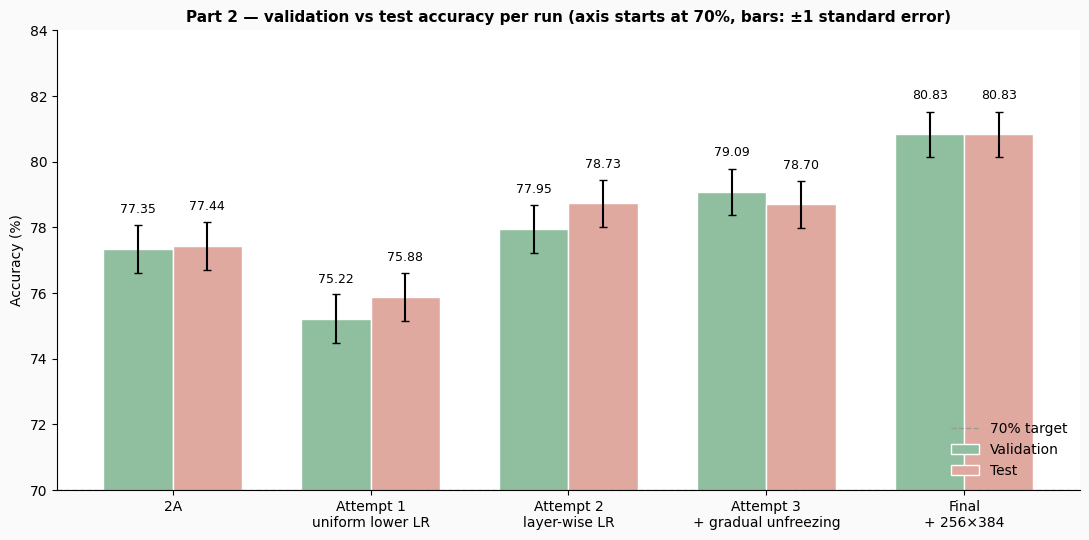

In [ ]:
# (label, resolution, validation history, best val accuracy, state_dict, test loader)
runs = [
    ("2A: Part 1 hyperparameters",             "224×320", history_2a, acc_2a, state_2a, loader_test_resnet),
    ("2B - Attempt 1: lower uniform learning rate", "224×320", history_1,  acc_1,  state_1,  loader_test_resnet),
    ("2B - Attempt 2: layer-wise learning rates",   "224×320", history_2,  acc_2,  state_2,  loader_test_resnet),
    ("2B - Attempt 3: + gradual unfreezing",        "224×320", history_3,  acc_3,  state_3,  loader_test_resnet),
    ("2B - Final solution: + higher resolution",    "256×384", history_4,  acc_4,  state_4,  loader_test_hr),
]

# validation and test accuracy of every run
rows = []
for name, res, h, val_acc, state, loader in runs:
    rows.append({"Run": name,
                 "Resolution": res,
                 "Validation acc. (%)": 100 * val_acc,
                 "Test acc. (%)": 100 * test_accuracy(state, loader)[1]})
df = pd.DataFrame(rows).set_index("Run")

# best value of each accuracy column highlighted
display(df.style
        .format({"Validation acc. (%)": "{:.2f}", "Test acc. (%)": "{:.2f}"})
        .highlight_max(subset=["Validation acc. (%)", "Test acc. (%)"],
                       props="font-weight: bold; background-color: #DDEBF7;")
        .set_properties(subset=["Resolution"], **{"text-align": "center"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}]))

# validation vs test accuracy of every run, as grouped bars
short_names = ["2A", "Attempt 1\nuniform lower LR", "Attempt 2\nlayer-wise LR",
               "Attempt 3\n+ gradual unfreezing", "Final\n+ 256×384"]
val = df["Validation acc. (%)"].values
test = df["Test acc. (%)"].values
n_eval = 3333                                  # images in the validation and test splits
err = lambda a: 100 * np.sqrt((a / 100) * (1 - a / 100) / n_eval)   # standard error (%)

x = np.arange(len(short_names))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5), facecolor="#FAFAFA")
ax.bar(x - width/2, val, width, yerr=err(val), capsize=3, label="Validation", color="#8FBF9F", edgecolor="white")
ax.bar(x + width/2, test, width, yerr=err(test), capsize=3, label="Test", color="#E0A9A0", edgecolor="white")

for i, (v, t) in enumerate(zip(val, test)):
    ax.text(i - width/2, v + 1.0, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.text(i + width/2, t + 1.0, f"{t:.2f}", ha="center", va="bottom", fontsize=9)

ax.axhline(70, color="#999999", linestyle="--", linewidth=1, label="70% target")
ax.set_ylim(70, 84)                            # axis starts at 70% to make the differences visible
ax.set_xticks(x); ax.set_xticklabels(short_names)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Part 2 — validation vs test accuracy per run (axis starts at 70%, bars: ±1 standard error)",
             fontsize=11, fontweight="bold")
ax.legend(frameon=False, loc="lower right")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

The largest gaps are between Attempt 1 and the layer-wise runs, and between Attempt 3 and the final solution; the difference between Attempt 2 and Attempt 3 is within the error bars.

### Final considerations

Fine-tuning the pretrained ResNet-18 with Part 1's hyperparameters already gives 77.44% on the test set (2A), well above the ~70% target. The final solution, based on the course recommendations for fine-tuning, raises it to **80.83%** (test loss 0.96). Its main components contributed differently:

- a uniform lower learning rate was not enough and lowered the accuracy (Attempt 1, 75.88% on test);
- layer-wise learning rates recovered that drop and slightly improved on 2A (Attempt 2, 78.73%);
- gradual unfreezing gave a small gain on validation but none on test (Attempt 3, 78.70%);
- the higher resolution gave the clearest improvement.

Validation and test accuracy agree within the noise for every run, so the choices made on the validation set carry over to the test set. The main remaining limitation is overfitting: training accuracy reaches 100% while validation stays around 80%. The training recipe already includes data augmentation, weight decay and label smoothing, so this gap is largely a consequence of the small amount of data (about 33 images per class), which a pretrained network can only partly compensate. Closing it further would mainly require more training data per class.

## Overall conclusions

**Part 1.** A CNN trained from scratch (five convolutional blocks with Batch Normalization, Global Average Pooling and Dropout, trained with Adam, a OneCycle schedule, weight decay, label smoothing and data augmentation) reaches 53.41% validation and 52.36% test accuracy on the 100 aircraft variants, above the ~50% target. The ablation shows that Batch Normalization is essential, that the scheduler, data augmentation, weight decay and the GAP + 5th block pair each add between 4 and 8 percentage points, and that Dropout and label smoothing have no measurable effect on accuracy. The gap between training (89.38%) and validation accuracy shows that, with about 33 images per class, the model is limited by overfitting.

**Part 2.** Starting from ImageNet weights is far more effective than training from scratch: with the same hyperparameters as Part 1, ResNet-18 already reaches 77.44% test accuracy (2A), against 52.36% for the network trained from scratch. Following the course recommendations for fine-tuning (layer-wise learning rates and gradual unfreezing) and increasing the input resolution to 256×384, the test accuracy rises to **80.83%** (2B), well above the ~70% target. Layer-wise learning rates and the higher resolution gave the clearest improvements, while the effect of gradual unfreezing alone was within the noise.

With about 33 images per class, the starting point matters a great deal: pretrained features give a gain of about 25 percentage points in test accuracy over a network trained from scratch, more than any single component of the latter except Batch Normalization, without which it barely trains. How the pretrained features are fine-tuned still matters, but its effect is smaller (about 3.4 percentage points of test accuracy over the baseline fine-tuning). In both parts, what limits the final accuracy is overfitting.